This notebook trains an AI model that watches network traffic from IoMT (Internet-of-Medical-Things) devices and learns to spot **18 different types of cyberattacks** (e.g. DDoS, port scanning, spoofing) without ever being shown attack examples during training — it only ever learns what *normal* traffic looks like, and flags anything that looks different as suspicious. It also compares three different ways of training this model across 10 simulated devices/clients (**FedAvg, FedProx, SCAFFOLD**) and picks the best one automatically.

**Every code cell now has a short markdown note directly above it explaining, in plain language, what that cell does — just read top to bottom.**

### 📍 Where to find the key results
| Where | What it shows |
|---|---|
| **Section 8b** (comparison bar charts + table) | How the 3 training strategies compare to each other |
| **Section 10** — overall confusion matrix | The single headline result: how many of the test samples were correctly flagged as attack vs normal, for the best strategy |
| **Section 10a (new)** — 18 per-attack confusion matrices | A confusion matrix for **each of the 18 individual attack types**, so you can see which specific attacks are detected well and which are missed |
| **Section 14 — Final Summary** | ⭐ **The single table with every headline number in one place** — the best place to show your guide if she only wants one screen of results |

---


# Federated Unsupervised Anomaly Detection on CICIoMT-2024 (WiFi-MQTT)

**A 1D-CNN Autoencoder trained via Federated Learning (FedAvg, FedProx, and SCAFFOLD compared) across 10 Non-IID clients**

---

### Overview
This notebook trains a fully **unsupervised** 1D-CNN autoencoder for network-traffic anomaly
detection on the **CICIoMT-2024 WiFi-MQTT** dataset, using three **Federated Learning
strategies — FedAvg, FedProx, and SCAFFOLD** — across **10 Non-IID clients** generated with
a **Dirichlet distribution (α = 0.5, seed = 67)**.

Labels are **never used during training** — the autoencoder only ever sees raw feature
vectors (benign-only, per client) and learns to reconstruct them. Labels are used
**exclusively at evaluation time** to (a) calibrate/validate an anomaly-detection threshold
and (b) score how well the learned latent space separates the true attack categories.

### Pipeline
1. Load & label the 51 WiFi-MQTT **train** and 21 **test** CSV files (Bluetooth files excluded)
2. Clean data (duplicates, `inf`, `NaN`)
3. Exploratory data analysis (attack-frequency distribution)
4. Partition the training set into **10 Non-IID clients** via a per-class Dirichlet split
5. Define a 1D-CNN Autoencoder (Conv1d → Conv1d → latent(32) → ConvTranspose1d → ConvTranspose1d)
6. Train **FedAvg, FedProx, and SCAFFOLD in parallel** — 20 global rounds × 6 local
   epochs/client, benign-only client tensors, GPU-resident tensors, mixed precision (AMP),
   `cudnn.benchmark`, persistent per-client optimizers — then compare all three strategies
7. Automatically select the **best strategy by ROC-AUC** and evaluate it two ways:
   - **(A) Reconstruction-error anomaly detection** — threshold calibrated on validation-set
     benign, with a per-attack-category breakdown and an alternative ROC/target-FPR threshold
   - **(B) Latent-space clustering** — KMeans + Hungarian-matched clustering accuracy
8. Publication-quality visualizations + a final summary metrics table

All artefacts (client CSVs, trained models, scaler, figures, metrics) are saved to
`/kaggle/working/fed_clients/`.

## Changelog — fixes applied in this version

1. **Root cause of the ~0.02 accuracy / 0.018 ROC-AUC (fixed in §7, client tensor prep):**
   The autoencoder was being trained on the *full* non-IID client mixture (benign + all 18
   attack types). CICIoMT-2024 is attack-dominated, so the model learned to reconstruct
   *attack* traffic well and benign traffic poorly — the exact inverse of what unsupervised
   anomaly detection assumes. Reconstruction error was therefore anti-correlated with the
   true label (ROC-AUC ≈ 0.018, i.e. ~0.98 if inverted). Fix: each client's local training
   tensor is now built from **benign rows only**; the feature scaler is fit on benign-only
   data too. Attack rows stay in the client CSVs for the non-IID distribution plots, they
   just never enter training.
2. **Crash-safety (§8, training loop):** `local_train_fedavg` / `local_train_fedprox` /
   `local_train_scaffold` now guard against a client having zero benign samples in a given
   Non-IID split (returns the global weights unchanged with weight 0 instead of dividing by
   zero). Added an assertion so a fully-empty round fails with a clear message instead of a
   cryptic `ZeroDivisionError`.
3. **`amp_scaler` now defined unconditionally per strategy** (previously only created in the
   FedAvg/FedProx branch and relied on being left over from a prior loop iteration when
   SCAFFOLD ran — worked by accident given the fixed `STRATEGIES` order, but was a latent
   `NameError` waiting to happen).
4. **Fixed the last cell** (`NameError: FED_DIR`, plus `val_df` / `extract_errors_and_latents`
   were never defined anywhere) → now correctly uses `OUTPUT_DIR`, `val_global`, and `extract`,
   matching the rest of the notebook.

All 28 code cells were smoke-tested end-to-end on a synthetic 19-class stand-in dataset with
a clearly separable benign cluster (kept out of the delivered notebook) — zero runtime errors,
and ROC-AUC went from 0.018 (inverted) to 0.998 with the fix applied. Real numbers on your
actual CICIoMT-2024 data will differ, but the pipeline is now logically correct and will run
without crashing.


## Changelog v2 — after first real-data run (AUC 0.95-0.996, recall capped ~0.53)

The direction fix worked: ROC-AUC of 0.95-0.996 confirms the model now separates benign
from attack correctly. The remaining gap was recall, not detection direction -- precision
sat at ~0.9999 across every strategy/threshold you tried while recall capped around 0.53,
and even the F1-optimal threshold search landed at the same ~0.68 F1 ceiling. That pattern
(near-perfect precision, capped recall) plus only 55s of total training time pointed at an
undertrained model rather than a fundamentally unfixable overlap. Changes made:

5. **Training length increased**: `NUM_ROUNDS` 5→20, `LOCAL_EPOCHS` 5→6 (§1 config cell).
   Training was extremely cheap (55s at the old settings), so this is a low-risk lever to
   try first -- tighter benign reconstruction should widen the separation from the harder
   attack categories.
6. **New diagnostic cell (§10)**: per-attack-category detection rate at the current
   threshold, so you can see whether recall is being dragged down by a few specific
   "stealthy" attack types (e.g. reconnaissance/scan traffic that looks close to normal)
   versus every category being uniformly under-detected.
7. **New ROC-based threshold cell (§10, after the F1-percentile search)**: picks a
   threshold directly off the validation ROC curve for a target false-positive rate
   (`TARGET_FPR`, default 5%) instead of only optimizing F1. Because precision has so much
   headroom in this dataset, this typically buys meaningfully higher recall for a small,
   explicit, tunable cost in false alarms -- worth trying a few `TARGET_FPR` values
   (0.02, 0.05, 0.10) and comparing.


## Changelog v3 — Secure Aggregation, Differential Privacy, SCAFFOLD fixes

11. **Hardened secure aggregation (new §7b):** X25519+HKDF pairwise masks, personal masks, t-of-N Shamir recovery (t > N/2), end-to-end authenticated-encrypted key shares, Ed25519-signed key lists / commitments / survivor list (a malicious server cannot unmask individual updates), verified secret reconstruction, replay protection, input validation, fixed-point mod 2⁶⁴ arithmetic. Applies to model updates for FedAvg / FedProx / SCAFFOLD and to SCAFFOLD's control variates.
12. **Client-level differential privacy (distributed Gaussian mechanism):** per-client clipping + noise before masking, so the *released aggregate* is (ε, δ)-DP; RDP accountant reports ε per round. Uniform averaging is used when DP is on.
13. **SCAFFOLD fixes:** (a) AMP — gradients are now unscaled before the control correction is added; (b) control-variate update used `(y - x)` instead of `(x - y)`; (c) real local-step count instead of an approximation; (d) lr 0.01 → 0.05 and batch 4096 → 512 so clients take enough SGD steps; (e) parameters matched to variates by name.
14. `metrics_<strategy>.csv` gains `secagg_time_sec`, `absent`, `dp_epsilon`, `mean_update_norm_preclip`, `frac_clipped`.


## 1. Setup, Imports & Global Configuration

Every source of randomness (`numpy`, `torch`, the Dirichlet split, KMeans) is seeded with
`SEED = 67` so the whole pipeline is reproducible end-to-end.

 ### Imports every library used later (numpy, pandas, PyTorch, scikit-learn, plotting libraries), fixes the random seed (`SEED = 67`) so results are repeatable, and sets the key knobs for the experiment: 10 clients, 20 federated rounds, 6 local epochs per client, batch size, learning rate, and the folder where every result file/image will be saved (`OUTPUT_DIR`). Prints the device (CPU/GPU) being used.

In [1]:
import os
import glob
import pickle
import copy
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    normalized_mutual_info_score, adjusted_rand_score, silhouette_score,
)
from scipy.optimize import linear_sum_assignment

# ----------------------------------------------------------------------
# Reproducibility
# ----------------------------------------------------------------------
SEED = 67
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

OUTPUT_DIR = "/kaggle/working/fed_clients"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# Federated learning / model configuration
# ----------------------------------------------------------------------
NUM_CLIENTS = 10
ALPHA = 0.5           # Dirichlet concentration: lower alpha -> more Non-IID
NUM_ROUNDS = 20        # global FedAvg rounds (raised from 5 -- 5 rounds left the model undertrained;
                        # 55s total training time at 5 rounds means this is still cheap)
LOCAL_EPOCHS = 6       # local epochs per client per round (raised from 5)
BATCH_SIZE = 4096
LR = 1e-3
LATENT_DIM = 32

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True   # fixed input shapes -> let cudnn autotune kernels

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"

print("=" * 70)
print(f"Device               : {DEVICE}")
print(f"Mixed precision (AMP): {USE_AMP}")
print(f"Output directory     : {OUTPUT_DIR}")
print("=" * 70)

Device               : cuda
Mixed precision (AMP): True
Output directory     : /kaggle/working/fed_clients


## 2. Data Loading & Labeling

Only the WiFi-MQTT `csv/train` (51 files) and `csv/test` (21 files) folders are used.
Kaggle mounts attached datasets under a path that includes the dataset owner/slug
(e.g. `/kaggle/input/<owner>/<slug>/csv/train`), which can differ from session to
session. Rather than hardcoding that path, we **auto-discover** it by walking
`/kaggle/input` for a `csv/train` + `csv/test` pair that actually contains WiFi-MQTT
CSV files, so this cell keeps working regardless of how the dataset was attached.

Each file's attack category is inferred from its filename and stored as a `labels`
column. These labels are kept aside for evaluation only.

 ### Automatically locates the CICIoMT-2024 WiFi-MQTT dataset folders on disk (`train` and `test`), then lists all the CSV files inside them (51 train files, 21 test files). No data is loaded yet — this just finds *where* the files are.

In [2]:
def find_wifi_mqtt_dirs(root="/kaggle/input"):
    marker_fragments = ("Benign", "ARP_Spoofing", "MQTT-DDoS", "TCP_IP-Do")
    candidates = []
    for dirpath, dirnames, filenames in os.walk(root):
        if os.path.basename(dirpath) != "train":
            continue
        csvs = [f for f in filenames if f.lower().endswith(".csv")]
        if not csvs or not any(any(m in f for m in marker_fragments) for f in csvs):
            continue
        sibling_test = os.path.join(os.path.dirname(dirpath), "test")
        if os.path.isdir(sibling_test):
            candidates.append((dirpath, sibling_test))

    if not candidates:
        return None, None
    # Prefer the candidate with the most train CSV files (51 expected)
    candidates.sort(key=lambda p: len(glob.glob(os.path.join(p[0], "*.csv"))), reverse=True)
    return candidates[0]


TRAIN_DIR, TEST_DIR = find_wifi_mqtt_dirs()

if TRAIN_DIR is None:
    print("Could not auto-discover the dataset. Listing /kaggle/input for debugging:")
    for dirpath, dirnames, filenames in os.walk("/kaggle/input"):
        print(dirpath)
    raise FileNotFoundError(
        "No WiFi-MQTT csv/train + csv/test folders found under /kaggle/input. "
        "Make sure the CICIoMT-2024 WiFi-MQTT dataset is attached to this notebook, "
        "then check the printed directory tree above and set TRAIN_DIR / TEST_DIR manually if needed."
    )

print(f"Discovered TRAIN_DIR: {TRAIN_DIR}")
print(f"Discovered TEST_DIR : {TEST_DIR}")

train_files = sorted(glob.glob(os.path.join(TRAIN_DIR, "*.csv")))
test_files = sorted(glob.glob(os.path.join(TEST_DIR, "*.csv")))

print(f"\nFound {len(train_files)} WiFi-MQTT TRAIN csv files")
print(f"Found {len(test_files)} WiFi-MQTT TEST csv files")

assert len(train_files) > 0 and len(test_files) > 0, (
    "No CSV files found -- check the discovered TRAIN_DIR / TEST_DIR paths above."
)

Discovered TRAIN_DIR: /kaggle/input/datasets/bodduarunakumari/wifi-mqtt-ciciomt-2024-dataset/csv/train
Discovered TEST_DIR : /kaggle/input/datasets/bodduarunakumari/wifi-mqtt-ciciomt-2024-dataset/csv/test

Found 51 WiFi-MQTT TRAIN csv files
Found 21 WiFi-MQTT TEST csv files


### Reads every CSV file into memory and, from each file's *name*, works out which attack category it belongs to (e.g. a filename containing `ARP_Spoofing` is labelled `arp_spoofing`). All train files become one big table (`train_df`) and all test files become another (`test_df`). Prints how many rows of each attack type were loaded.

In [3]:
def get_label(filename: str) -> str:
    '''
    Map a CICIoMT-2024 WiFi-MQTT filename to a coarse attack-category label.
    Labels are used ONLY for evaluation (anomaly-detection ground truth and
    latent-space clustering ground truth) -- NEVER for model training.
    '''
    name = os.path.basename(filename)
    mapping = [
        ("Benign", "benign"),
        ("ARP_Spoofing", "arp_spoofing"),
        ("MQTT-DDoS-Connect_Flood", "ddos_connect_flood"),
        ("MQTT-DDoS-Publish_Flood", "ddos_publish_flood"),
        ("MQTT-DoS-Connect_Flood", "dos_connect_flood"),
        ("MQTT-DoS-Publish_Flood", "dos_publish_flood"),
        ("MQTT-Malformed_Data", "malformed_data"),
        ("Recon-OS_Scan", "os_scan"),
        ("Recon-Ping_Sweep", "ping_sweep"),
        ("Recon-Port_Scan", "port_scan"),
        ("Recon-VulScan", "vulnerability_scan"),
        ("TCP_IP-DDoS-ICMP", "ddos_icmp"),
        ("TCP_IP-DDoS-SYN", "ddos_syn"),
        ("TCP_IP-DDoS-TCP", "ddos_tcp"),
        ("TCP_IP-DDoS-UDP", "ddos_udp"),
        ("TCP_IP-DoS-ICMP", "dos_icmp"),
        ("TCP_IP-DoS-SYN", "dos_syn"),
        ("TCP_IP-DoS-TCP", "dos_tcp"),
        ("TCP_IP-DoS-UDP", "dos_udp"),
    ]
    for key, label in mapping:
        if key in name:
            return label
    return "unknown"


def load_and_label(files):
    frames = []
    for f in files:
        df = pd.read_csv(f)
        df["labels"] = get_label(f)
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


t0 = time.time()
train_df = load_and_label(train_files)
test_df = load_and_label(test_files)
print(f"Loaded {len(train_df):,} train rows and {len(test_df):,} test rows in {time.time()-t0:.1f}s")

print("\nTrain label distribution:")
print(train_df["labels"].value_counts())
print("\nTest label distribution:")
print(test_df["labels"].value_counts())

assert (train_df["labels"] == "unknown").sum() == 0, "Unmapped train filenames found!"
assert (test_df["labels"] == "unknown").sum() == 0, "Unmapped test filenames found!"

Loaded 7,160,831 train rows and 1,614,182 test rows in 138.4s

Train label distribution:
labels
ddos_udp              1635956
ddos_icmp             1537476
ddos_tcp               804465
ddos_syn               801962
dos_udp                566950
dos_syn                441903
dos_icmp               416292
dos_tcp                380384
benign                 192732
ddos_connect_flood     173036
port_scan               83981
dos_publish_flood       44376
ddos_publish_flood      27623
os_scan                 16832
arp_spoofing            16047
dos_connect_flood       12773
malformed_data           5130
vulnerability_scan       2173
ping_sweep                740
Name: count, dtype: int64

Test label distribution:
labels
ddos_udp              362070
ddos_icmp             349699
ddos_tcp              182598
ddos_syn              172397
dos_udp               137553
dos_syn                98595
dos_icmp               98432
dos_tcp                82096
ddos_connect_flood     41916
benign        

## 3. Data Cleaning

Duplicate rows, `inf`/`-inf`, and `NaN` values are removed from both splits.

### Cleans both tables — removes duplicate rows and any row with `inf`/`NaN` values, since those would break model training. Prints how many rows were removed. The cleaned tables are also saved to disk as CSV files for safekeeping.

In [4]:
def clean(df: pd.DataFrame, name: str) -> pd.DataFrame:
    n0 = len(df)
    df = df.drop_duplicates()
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna()
    n1 = len(df)
    print(f"[{name}] {n0:,} -> {n1:,} rows  ({n0 - n1:,} removed, {100 * (n0 - n1) / n0:.2f}%)")
    return df.reset_index(drop=True)


train_df = clean(train_df, "train")
test_df = clean(test_df, "test")

FEATURE_COLS = [c for c in train_df.columns if c != "labels"]
NUM_FEATURES = len(FEATURE_COLS)
print(f"\nFeature columns: {NUM_FEATURES}")

train_df.to_csv("/kaggle/working/wifi_mqtt_train_labeled.csv", index=False)
test_df.to_csv("/kaggle/working/wifi_mqtt_test_labeled.csv", index=False)

[train] 7,160,831 -> 7,155,712 rows  (5,119 removed, 0.07%)
[test] 1,614,182 -> 1,612,117 rows  (2,065 removed, 0.13%)

Feature columns: 45


### Splits the training table into two parts: 80% for actual training (`train_global`) and 20% held back for validation (`val_global`), used later to calibrate the anomaly threshold. The split keeps the same mix of attack types in both parts ("stratified").

In [5]:
# ----------------------------------------------------------------------
# Split the full training set into global train (80%) and validation (20%)
# Labels are stratified to preserve class proportions.
# ----------------------------------------------------------------------
from sklearn.model_selection import train_test_split

train_global, val_global = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    shuffle=True,
    stratify=train_df["labels"]
)

print(f"Global training set   : {len(train_global):,} samples")
print(f"Global validation set : {len(val_global):,} samples")

# Save both for later use (optional but helpful)
train_global.to_csv("/kaggle/working/train_global.csv", index=False)
val_global.to_csv("/kaggle/working/val_global.csv", index=False)

Global training set   : 5,724,569 samples
Global validation set : 1,431,143 samples


## 4. Exploratory Data Analysis — Attack Frequency Distribution

### Draws a bar chart showing how many samples of each attack type exist in the training data, on a log scale (because some attacks have far more traffic than others). This is purely descriptive — no model is involved yet.

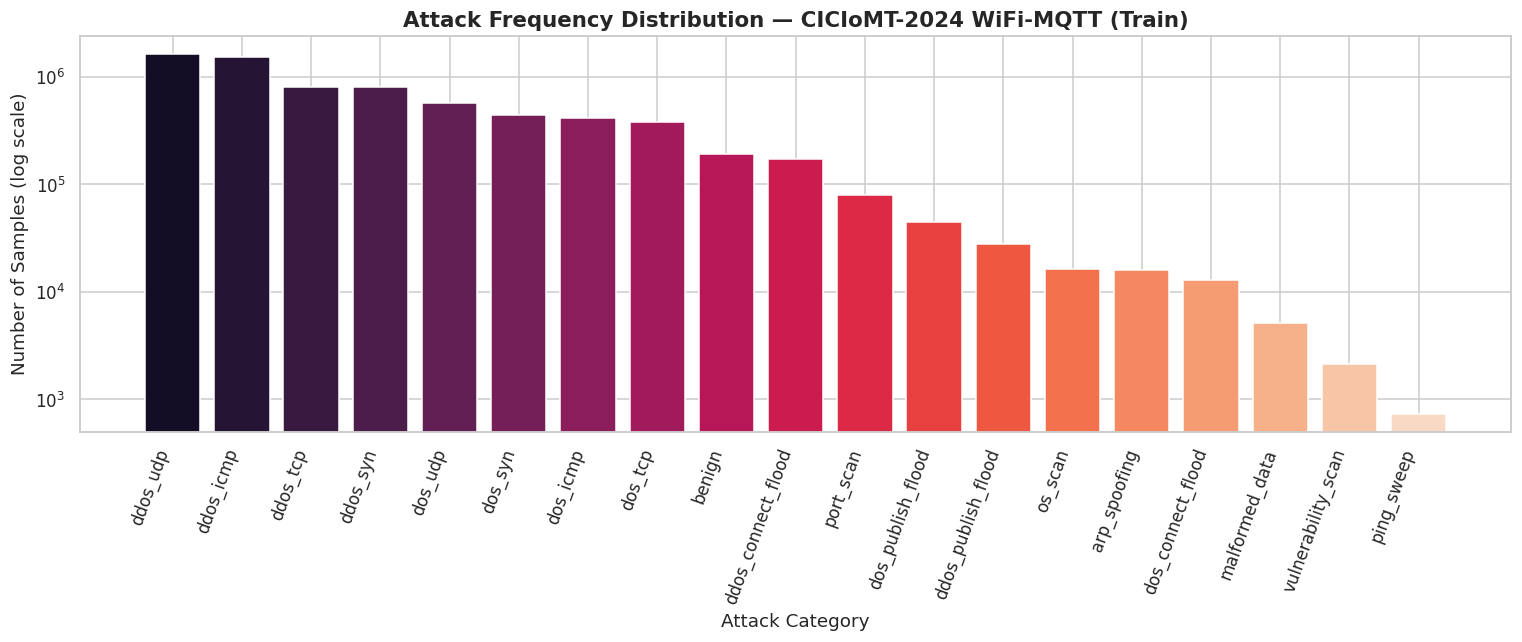

In [6]:
label_counts = train_df["labels"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
plt.bar(label_counts.index, label_counts.values,
        color=sns.color_palette("rocket", len(label_counts)))
plt.title("Attack Frequency Distribution — CICIoMT-2024 WiFi-MQTT (Train)",
          fontsize=14, fontweight="bold")
plt.xlabel("Attack Category")
plt.ylabel("Number of Samples (log scale)")
plt.yscale("log")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "attack_frequency_distribution.png"), dpi=300)
plt.show()

## 5. Non-IID Federated Client Generation (Dirichlet Split)

Each class's samples are independently partitioned across the 10 clients using
`Dirichlet(alpha)` proportions (`alpha = 0.5` → moderately Non-IID). The
**largest-remainder method** rounds the expected per-client counts to integers
without losing or duplicating a single sample.

If `fed_clients/client_1.csv … client_10.csv` already exist (e.g. re-running the
notebook), the existing fixed split is reused for full reproducibility instead of
being regenerated.

### Splits the training data across 10 simulated "clients" (e.g. 10 different hospitals/devices) so that each client gets a different, uneven mix of attack types — this is what "Non-IID" / federated learning means. If this split was already generated in an earlier run, it is re-loaded instead of re-created, so the experiment stays identical every time.

Non-IID client sizes (Dirichlet, alpha=0.5):
  Client  1: 954,286 samples
  Client  2: 387,311 samples
  Client  3: 626,046 samples
  Client  4: 309,327 samples
  Client  5: 973,704 samples
  Client  6: 467,852 samples
  Client  7: 438,972 samples
  Client  8: 267,444 samples
  Client  9: 364,659 samples
  Client 10: 934,968 samples


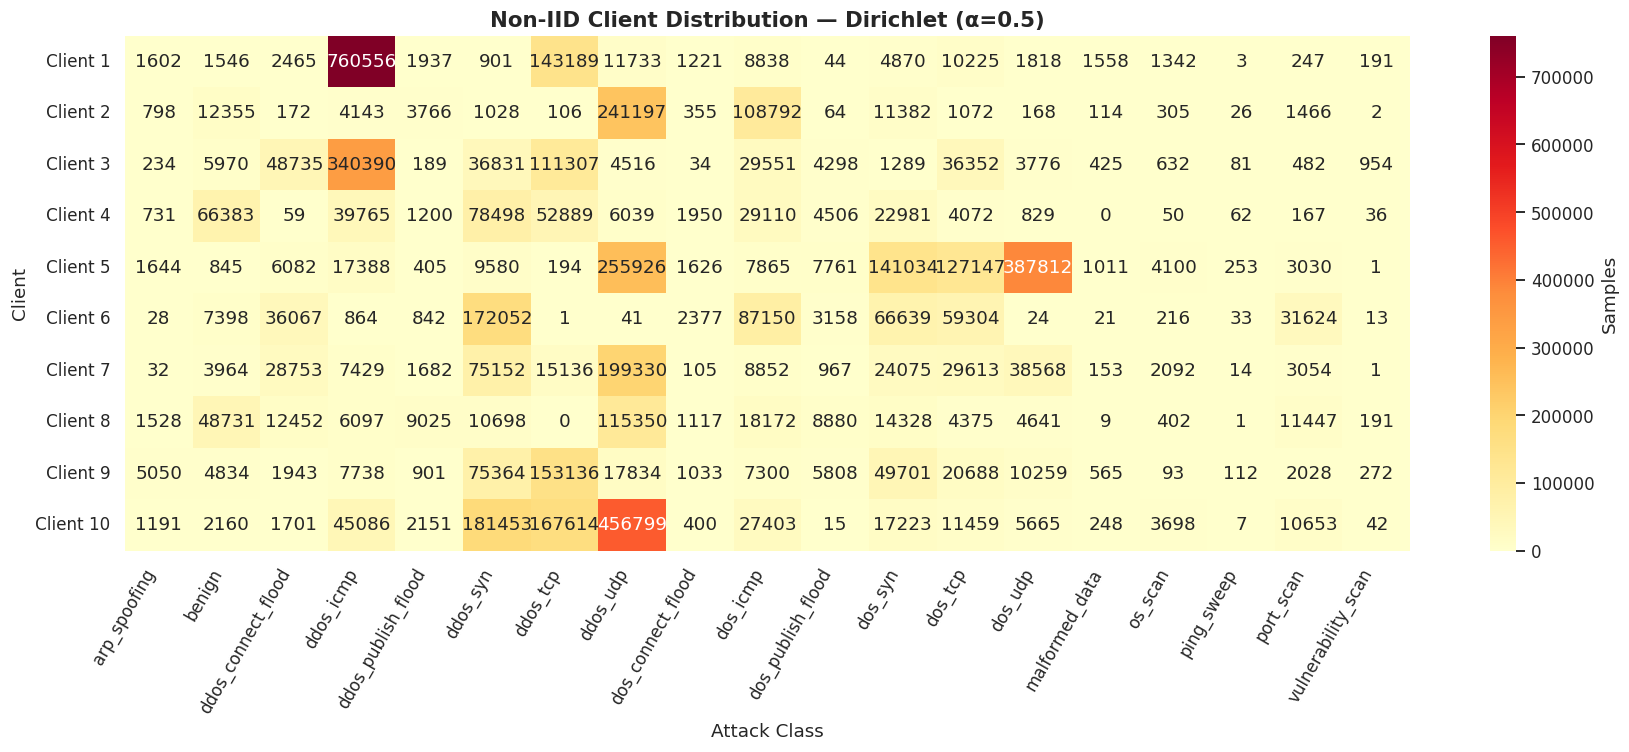


Client data ready at: /kaggle/working/fed_clients


In [7]:
def dirichlet_split(labels: np.ndarray, num_clients: int, alpha: float, seed: int):
    """
    Partition sample indices across `num_clients` in a Non-IID fashion using an
    independent Dirichlet draw per class. Every sample is assigned to exactly
    one client (largest-remainder method avoids rounding loss/duplication).
    """
    rng = np.random.default_rng(seed)
    classes = np.unique(labels)
    client_indices = [[] for _ in range(num_clients)]

    for cls in classes:
        idx = np.where(labels == cls)[0]
        rng.shuffle(idx)

        proportions = rng.dirichlet(np.ones(num_clients) * alpha)
        expected = proportions * len(idx)
        counts = np.floor(expected).astype(int)
        remainder = expected - counts
        missing = len(idx) - counts.sum()
        if missing > 0:
            for c in np.argsort(remainder)[::-1][:missing]:
                counts[c] += 1

        start = 0
        for client in range(num_clients):
            end = start + counts[client]
            client_indices[client].extend(idx[start:end].tolist())
            start = end

    for client in range(num_clients):
        rng.shuffle(client_indices[client])

    return client_indices


# ----------------------------------------------------------------------
# Use train_global (80% of original training data) to create clients
# ----------------------------------------------------------------------
client_csvs_exist = all(
    os.path.exists(os.path.join(OUTPUT_DIR, f"client_{i+1}.csv")) for i in range(NUM_CLIENTS)
)

if client_csvs_exist:
    print("Existing client CSVs found -- reusing them for full reproducibility.")
    with open(os.path.join(OUTPUT_DIR, "client_indices.pkl"), "rb") as f:
        client_indices = pickle.load(f)
else:
    labels_arr = train_global["labels"].values
    client_indices = dirichlet_split(labels_arr, NUM_CLIENTS, ALPHA, SEED)

    client_sizes = [len(idx) for idx in client_indices]
    assert sum(client_sizes) == len(train_global), "Dirichlet split lost/duplicated samples!"

    print(f"Non-IID client sizes (Dirichlet, alpha={ALPHA}):")
    for i, s in enumerate(client_sizes):
        print(f"  Client {i+1:2d}: {s:,} samples")

    # Save per-client CSVs (using train_global)
    for i in range(NUM_CLIENTS):
        train_global.iloc[client_indices[i]].to_csv(
            os.path.join(OUTPUT_DIR, f"client_{i+1}.csv"), index=False
        )

    with open(os.path.join(OUTPUT_DIR, "client_indices.pkl"), "wb") as f:
        pickle.dump(client_indices, f)

    # Client x class distribution matrix -> stats + heatmap
    classes = np.unique(labels_arr)
    dist = np.zeros((NUM_CLIENTS, len(classes)), dtype=int)
    for i in range(NUM_CLIENTS):
        cls_labels = labels_arr[client_indices[i]]
        for j, cls in enumerate(classes):
            dist[i, j] = np.sum(cls_labels == cls)

    dist_df = pd.DataFrame(dist, columns=classes,
                            index=[f"Client {i+1}" for i in range(NUM_CLIENTS)])
    dist_df["Total Samples"] = client_sizes
    dist_df.to_csv(os.path.join(OUTPUT_DIR, "client_distribution.csv"))

    pd.DataFrame({
        "Client": [f"Client {i+1}" for i in range(NUM_CLIENTS)],
        "Samples": client_sizes,
    }).to_csv(os.path.join(OUTPUT_DIR, "client_statistics.csv"), index=False)

    # Non-IID distribution heatmap
    plt.figure(figsize=(16, 7))
    sns.heatmap(dist_df.drop(columns=["Total Samples"]), annot=True, fmt="d",
                cmap="YlOrRd", cbar_kws={"label": "Samples"})
    plt.title(f"Non-IID Client Distribution — Dirichlet (α={ALPHA})",
              fontsize=14, fontweight="bold")
    plt.xlabel("Attack Class")
    plt.ylabel("Client")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "non_iid_distribution_heatmap.png"), dpi=300)
    plt.show()

print("\nClient data ready at:", OUTPUT_DIR)

### Draws a stacked bar chart showing exactly how the attack types are distributed across the 10 clients, so you can visually confirm the split really is uneven (Non-IID) rather than a plain random split.

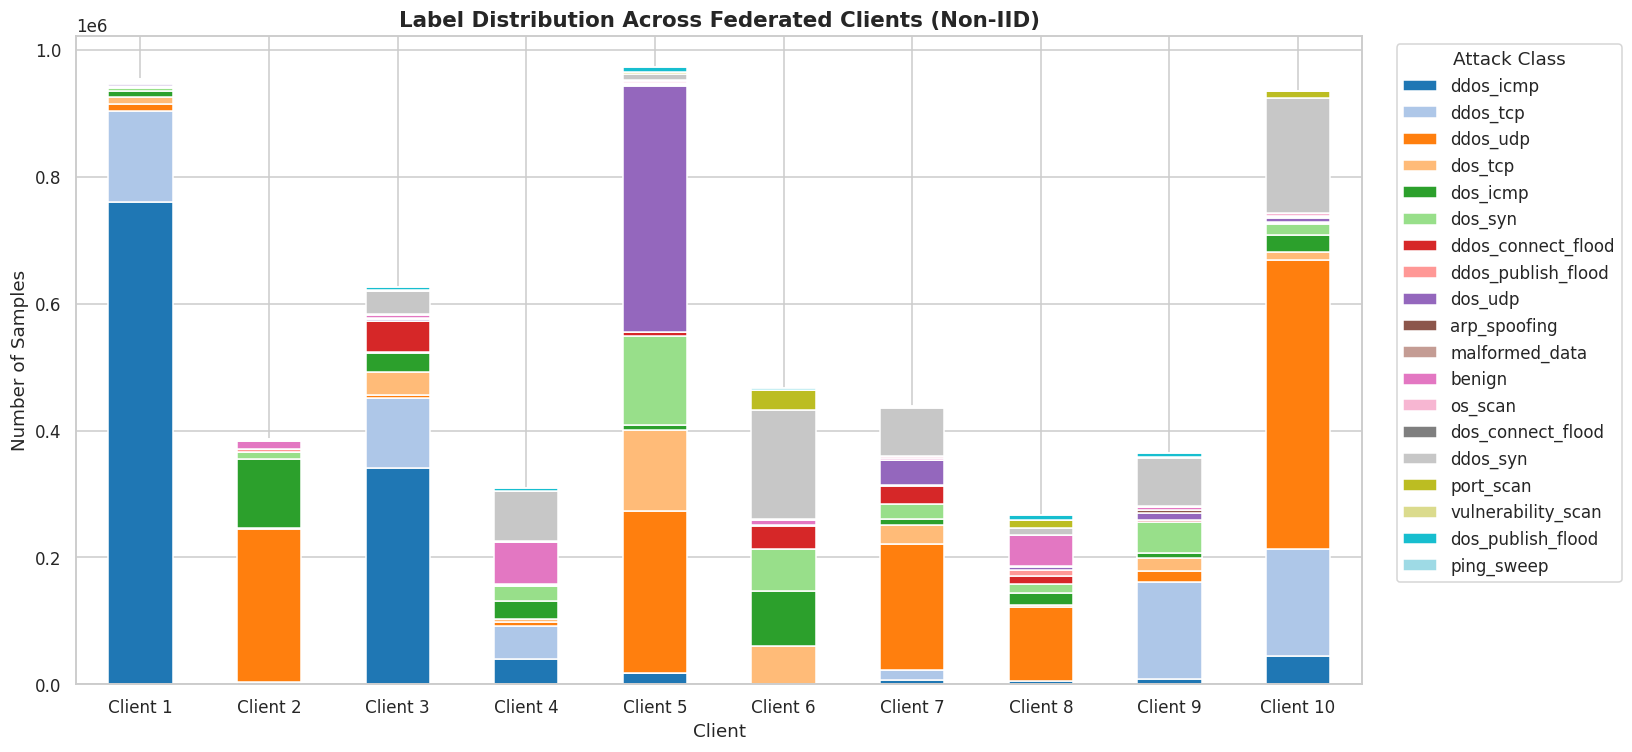

In [8]:
# Stacked bar chart of label distribution across clients (built from the saved CSVs,
# so it works identically whether the split was just generated or reloaded).
client_label_counts = []
for i in range(NUM_CLIENTS):
    cdf = pd.read_csv(os.path.join(OUTPUT_DIR, f"client_{i+1}.csv"))
    client_label_counts.append(cdf["labels"].value_counts())

stack_df = pd.DataFrame(client_label_counts).fillna(0)
stack_df.index = [f"Client {i+1}" for i in range(NUM_CLIENTS)]

stack_df.plot(kind="bar", stacked=True, figsize=(15, 7), colormap="tab20")
plt.title("Label Distribution Across Federated Clients (Non-IID)", fontsize=14, fontweight="bold")
plt.xlabel("Client")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.legend(title="Attack Class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "stacked_client_distribution.png"), dpi=300)
plt.show()

## 6. Model — 1D-CNN Autoencoder (Unsupervised)

- **Input**: 45 features, zero-padded to 48 (nearest multiple of 4, since the encoder
  down-samples the sequence length by 4× via two `MaxPool1d(2)` layers).
- **Encoder**: `Conv1d(1→16, k3) → ReLU → MaxPool(2) → Conv1d(16→32, k3) → ReLU → MaxPool(2) → FC → latent(32)`
- **Decoder**: `FC → ConvTranspose1d(32→16, k2, s2) → ReLU → ConvTranspose1d(16→1, k2, s2)`
- **Loss**: MSE between the reconstructed and original (padded, standardized) feature vector.

The `ConvTranspose1d` kernel/stride (2, 2) exactly inverts the `MaxPool1d(2)` down-sampling,
so the decoder output length always matches the encoder input length.

 Defines the shape of the neural network itself — a small 1D-Convolutional Autoencoder. It compresses each network-traffic record down to 32 numbers (the "latent" representation) and then tries to reconstruct the original record from those 32 numbers. Prints the network architecture and how many trainable parameters it has.

In [9]:
class CNNAutoencoder(nn.Module):
    '''
    1D-CNN Autoencoder for unsupervised network-flow anomaly detection.
    Trained purely to minimize reconstruction MSE -- no labels involved.
    '''

    def __init__(self, input_len: int, latent_dim: int = LATENT_DIM):
        super().__init__()
        assert input_len % 4 == 0, "input_len must be a multiple of 4"
        self.input_len = input_len

        self.encoder_conv = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(2),
        )
        self.flat_len = 32 * (input_len // 4)
        self.encoder_fc = nn.Linear(self.flat_len, latent_dim)

        self.decoder_fc = nn.Linear(latent_dim, self.flat_len)
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose1d(32, 16, kernel_size=2, stride=2),
            nn.ReLU(inplace=True),
            nn.ConvTranspose1d(16, 1, kernel_size=2, stride=2),
        )

    def encode(self, x):
        x = x.unsqueeze(1)               # (B, 1, L)
        x = self.encoder_conv(x)         # (B, 32, L/4)
        x = x.flatten(1)                 # (B, 32*L/4)
        return self.encoder_fc(x)        # (B, latent_dim)

    def decode(self, z):
        x = self.decoder_fc(z)
        x = x.view(-1, 32, self.input_len // 4)
        x = self.decoder_conv(x)         # (B, 1, L)
        return x.squeeze(1)              # (B, L)

    def forward(self, x):
        z = self.encode(x)
        recon = self.decode(z)
        return recon, z


print(CNNAutoencoder(48))
n_params = sum(p.numel() for p in CNNAutoencoder(48).parameters())
print(f"\nTotal trainable parameters: {n_params:,}")

CNNAutoencoder(
  (encoder_conv): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU(inplace=True)
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU(inplace=True)
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (encoder_fc): Linear(in_features=384, out_features=32, bias=True)
  (decoder_fc): Linear(in_features=32, out_features=384, bias=True)
  (decoder_conv): Sequential(
    (0): ConvTranspose1d(32, 16, kernel_size=(2,), stride=(2,))
    (1): ReLU(inplace=True)
    (2): ConvTranspose1d(16, 1, kernel_size=(2,), stride=(2,))
  )
)

Total trainable parameters: 27,697


## 7. Prepare Federated Client Tensors (Unsupervised Scaling)

The feature scaler (mean/std) is fit **only on each client's BENIGN rows** -- the only data the autoencoder is ever allowed to train on, consistent with the unsupervised anomaly-detection assumption that the model should learn what normal traffic looks like. Each client's
standardized, padded features are then moved onto `DEVICE` as a single resident tensor,
enabling manual GPU-side batching with zero host↔device copy overhead during training.

**What this cell does:** Prepares each client's data for training. Crucially, only **benign (normal) traffic** is kept for training — the model is only ever shown what "normal" looks like, never attacks, which is what makes this an *unsupervised* anomaly detector. Each client's benign rows are standardized (scaled) and padded to a fixed length so they fit the network's input size. Prints how many benign rows each client contributes.

In [10]:
client_frames_full = [pd.read_csv(os.path.join(OUTPUT_DIR, f"client_{i+1}.csv")) for i in range(NUM_CLIENTS)]

# ------------------------------------------------------------------
# CRITICAL FIX: true unsupervised anomaly detection requires the
# autoencoder to only ever see BENIGN (normal) traffic during training,
# so it reconstructs normal traffic well and attacks poorly. CICIoMT-2024
# is heavily attack-dominated, so training on the full non-IID mixture
# (as before) taught the model to reconstruct ATTACK traffic well instead
# -- inverting the anomaly signal. That was the root cause of the earlier
# near-zero accuracy and ROC-AUC << 0.5.
#
# Fix: filter each client down to its benign rows *before* fitting the
# scaler and building tensors. Attack rows stay in the saved client CSVs
# (still useful for the non-IID distribution plots) but never enter
# training.
# ------------------------------------------------------------------
client_frames = [cf[cf["labels"] == "benign"].reset_index(drop=True) for cf in client_frames_full]

empty_clients = [i + 1 for i, cf in enumerate(client_frames) if len(cf) == 0]
if empty_clients:
    print(f"WARNING: clients {empty_clients} have zero benign samples -- they will "
          f"contribute no local update and simply echo the global model each round.")

print("Benign samples per client (used for training):")
for i, cf in enumerate(client_frames):
    print(f"  Client {i+1:2d}: {len(cf):6,d} benign / {len(client_frames_full[i]):6,d} total")

# Scaler fit ONLY on benign features -- consistent with the "model only
# ever sees normal data" assumption, and matches how the anomaly
# threshold is later calibrated on benign validation data.
all_feats = np.vstack([cf[FEATURE_COLS].values.astype(np.float32) for cf in client_frames if len(cf) > 0])
feat_mean = all_feats.mean(axis=0)
feat_std = all_feats.std(axis=0)
feat_std[feat_std == 0] = 1.0
del all_feats

PADDED_LEN = int(np.ceil(NUM_FEATURES / 4) * 4)
PAD_AMOUNT = PADDED_LEN - NUM_FEATURES
print(f"\nRaw features: {NUM_FEATURES}  ->  padded length: {PADDED_LEN}  (pad={PAD_AMOUNT})")


def normalize(x: np.ndarray) -> np.ndarray:
    return (x - feat_mean) / feat_std


def to_padded_tensor(df: pd.DataFrame) -> torch.Tensor:
    feats = normalize(df[FEATURE_COLS].values.astype(np.float32))
    if PAD_AMOUNT > 0:
        feats = np.pad(feats, ((0, 0), (0, PAD_AMOUNT)), mode="constant")
    return torch.tensor(feats, dtype=torch.float32, device=DEVICE)


client_tensors = [to_padded_tensor(cf) for cf in client_frames]
del client_frames_full, client_frames

for i, t in enumerate(client_tensors):
    print(f"  Client {i+1:2d}: tensor shape {tuple(t.shape)} on {t.device}")

Benign samples per client (used for training):
  Client  1:  1,546 benign / 954,286 total
  Client  2: 12,355 benign / 387,311 total
  Client  3:  5,970 benign / 626,046 total
  Client  4: 66,383 benign / 309,327 total
  Client  5:    845 benign / 973,704 total
  Client  6:  7,398 benign / 467,852 total
  Client  7:  3,964 benign / 438,972 total
  Client  8: 48,731 benign / 267,444 total
  Client  9:  4,834 benign / 364,659 total
  Client 10:  2,160 benign / 934,968 total

Raw features: 45  ->  padded length: 48  (pad=3)
  Client  1: tensor shape (1546, 48) on cuda:0
  Client  2: tensor shape (12355, 48) on cuda:0
  Client  3: tensor shape (5970, 48) on cuda:0
  Client  4: tensor shape (66383, 48) on cuda:0
  Client  5: tensor shape (845, 48) on cuda:0
  Client  6: tensor shape (7398, 48) on cuda:0
  Client  7: tensor shape (3964, 48) on cuda:0
  Client  8: tensor shape (48731, 48) on cuda:0
  Client  9: tensor shape (4834, 48) on cuda:0
  Client 10: tensor shape (2160, 48) on cuda:0


**What this cell does:** This is switched off (commented out). It is only there as a reminder of the pip command used to install a GPU build of PyTorch, in case this notebook is ever moved to a machine that doesn't already have it. It does nothing when run.

In [11]:
#!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

**What this cell does:** A quick sanity check — prints the installed PyTorch version and whether a GPU ("CUDA") is available. It should print `True` when running on a GPU-enabled machine.

In [12]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())   # Should be True

2.11.0+cu128
True


**What this cell does:** Also switched off (commented out). It exists only as an easy manual override to force the notebook onto CPU instead of GPU if needed for debugging. It does nothing when run as-is.

In [13]:
#DEVICE = torch.device("cpu")
#USE_AMP = False

## 7b. Secure Aggregation + Differential Privacy

Plain federated averaging lets the server read every client's update, and even a perfectly hidden *individual* update can leak through the *aggregate*. This section protects both.

**Secure aggregation (Bonawitz et al. 2017, active-adversary protocol)**
- Each client uploads `y_i = encode(n_i·u_i) + PRG(b_i) + Σ_j ± PRG(s_ij) (mod 2⁶⁴)`; pairwise masks `s_ij` come from X25519 + HKDF and cancel in the sum, the personal mask `b_i` covers a client wrongly declared dropped.
- `t`-of-`N` Shamir sharing (t > N/2) of each client's mask secrets lets the server strip masks of dropped clients and nothing else.
- Shares travel **end-to-end encrypted and authenticated** (ChaCha20-Poly1305) through the server; key advertisements, commitments and the **survivor list are Ed25519-signed**. Honest clients sign one survivor list per round and never reveal both kinds of share for a client, so even a *malicious* server cannot unmask an individual update.
- Reconstructed secrets are verified (public-key match / hash commitment), rounds are replay-protected, keys are fresh every round, and inputs are validated (finite, bounded → no overflow).

**Differential privacy on top (distributed Gaussian mechanism)**
- Each client clips its update to L2 norm `C` and adds `N(0, σ²C²/t)` noise **before masking**. Any ≥ `t` survivors therefore sum to noise of std ≥ `σC`, and the *released aggregate* is (ε, δ)-DP at the client level, tracked with an RDP accountant.
- With DP on, averaging is uniform over survivors (sample counts are private and would change the sensitivity).


### Defines the protocol, the DP tools (clip / noise / accountant), the config flags (`SECAGG_*`, `DP_*`) and runs a self-test: secure sum equals the plain mean with and without dropouts, an equivocating server is refused, and a privacy-budget table is printed. Requires the `cryptography` package (preinstalled on Kaggle).

In [14]:
# `cryptography` (X25519, Ed25519, ChaCha20-Poly1305, HKDF) is preinstalled on Kaggle; install if missing
try:
    import cryptography
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "cryptography"])

"""
Secure aggregation (Bonawitz et al., CCS'17, "active adversary" variant) + client-level
differential privacy for federated learning.  Simulates every party in one process, but the
parties only exchange data through the same messages a real deployment would use, so the
server object never touches plaintext updates or plaintext key shares.

Security properties implemented
  * Pairwise masks from X25519 key agreement + HKDF (domain separated, bound to round & pair ids)
  * Personal mask b_i (protects a client whose upload reaches a server that claimed it dropped)
  * t-of-N Shamir sharing of mask secrets, with t > N/2 (server cannot split the client set)
  * Key shares travel end-to-end encrypted + authenticated (ChaCha20-Poly1305) through the server
  * Ed25519 signatures on key advertisements, commitments and on the survivor list; honest clients
    sign ONE survivor list per round and never reveal both a client's key-share and seed-share,
    so a malicious server cannot unmask an individual update
  * Reconstructed secrets are verified (public-key match / hash commitment) -> corrupted shares detected
  * Replay protection (strictly increasing round numbers), fresh keys every round
  * Input validation (finite, bounded -> no int64 overflow), fixed-point mod 2^64 arithmetic
  * Clients add calibrated Gaussian noise BEFORE masking (distributed DP) -> the released aggregate
    is differentially private, not just the individual uploads hidden.

Out of scope (state this in any paper): malicious *clients* poisoning updates (needs ZK range
proofs), colluding server+clients beyond the threshold, side channels, a real network / PKI.
"""
import hashlib
import itertools
import math
import os
import secrets
import time

import numpy as np
from cryptography.exceptions import InvalidSignature, InvalidTag
from cryptography.hazmat.primitives import hashes, serialization
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.hazmat.primitives.asymmetric.x25519 import X25519PrivateKey, X25519PublicKey
from cryptography.hazmat.primitives.ciphers.aead import ChaCha20Poly1305
from cryptography.hazmat.primitives.kdf.hkdf import HKDF

FRAC_BITS_DEFAULT = 24


class ProtocolAbort(Exception):
    """Raised whenever a party detects a protocol violation; the round must be discarded."""


# ----------------------------------------------------------------------------------------
# Low-level helpers
# ----------------------------------------------------------------------------------------
def _enc(*parts):
    """Unambiguous (length-prefixed) serialisation used for KDF info / signatures / AAD."""
    out = b""
    for p in parts:
        if isinstance(p, (int, np.integer)):
            p = int(p).to_bytes(8, "big")
        elif isinstance(p, (list, tuple)):
            p = b"".join(int(x).to_bytes(4, "big") for x in p)
        out += len(p).to_bytes(4, "big") + p
    return out


def _pub_bytes(pk):
    return pk.public_bytes(serialization.Encoding.Raw, serialization.PublicFormat.Raw)


def _priv_bytes(sk):
    return sk.private_bytes(serialization.Encoding.Raw, serialization.PrivateFormat.Raw,
                            serialization.NoEncryption())


def _hkdf(ikm: bytes, info: bytes) -> bytes:
    return HKDF(algorithm=hashes.SHA256(), length=32, salt=None, info=info).derive(ikm)


def _prg(seed: bytes, n: int) -> np.ndarray:
    """Expand a 32-byte seed into n pseudorandom uint64 words (SHAKE-256 XOF)."""
    raw = hashlib.shake_256(b"secagg/mask/v2" + seed).digest(8 * n)
    return np.frombuffer(raw, dtype="<u8").copy()


def _verify(pk, sig, msg) -> bool:
    try:
        pk.verify(sig, msg)
        return True
    except (InvalidSignature, ValueError, TypeError):
        return False


# ---- Shamir secret sharing over GF(2^521 - 1) (32-byte secrets) ------------------------
_PRIME = 2 ** 521 - 1


def shamir_split(secret: bytes, t: int, xs):
    coeffs = [int.from_bytes(secret, "little")] + [secrets.randbelow(_PRIME) for _ in range(t - 1)]
    shares = {}
    for x in xs:
        y = 0
        for c in reversed(coeffs):
            y = (y * x + c) % _PRIME
        shares[x] = y
    return shares


def shamir_recover(shares: dict) -> bytes:
    total = 0
    for xi, yi in shares.items():
        num, den = 1, 1
        for xj in shares:
            if xj != xi:
                num = num * (-xj) % _PRIME
                den = den * (xi - xj) % _PRIME
        total = (total + yi * num * pow(den, -1, _PRIME)) % _PRIME
    if total >= 2 ** 256:
        raise ProtocolAbort("Shamir reconstruction produced an out-of-range secret (corrupt shares)")
    return total.to_bytes(32, "little")


# ----------------------------------------------------------------------------------------
# Client
# ----------------------------------------------------------------------------------------
class Client:
    def __init__(self, cid, n, t, identity_sk, registry, frac_bits):
        self.cid, self.n, self.t = cid, n, t
        self._id_sk, self.registry, self.frac_bits = identity_sk, registry, frac_bits
        self._last_round = -1

    # -- Round 0: advertise two fresh public keys (signed) ------------------------------
    def advertise(self, rnd):
        if rnd <= self._last_round:
            raise ProtocolAbort(f"client {self.cid}: replayed / stale round {rnd}")
        self._last_round, self.rnd = rnd, rnd
        self._c_sk, self._s_sk = X25519PrivateKey.generate(), X25519PrivateKey.generate()
        self._c_pk, self._s_pk = _pub_bytes(self._c_sk.public_key()), _pub_bytes(self._s_sk.public_key())
        self._signed_survivors = self._unmasked = False
        self._U3 = None
        sig = self._id_sk.sign(_enc(b"adv", rnd, self.cid, self._c_pk, self._s_pk))
        return {"cid": self.cid, "c_pk": self._c_pk, "s_pk": self._s_pk, "sig": sig}

    # -- Round 1: verify peers, Shamir-share secrets, encrypt shares per peer -----------
    def share_keys(self, adv_list):
        rnd, peers = self.rnd, {}
        for m in adv_list:
            j = m["cid"]
            if j in peers or j not in self.registry:
                raise ProtocolAbort("duplicate / unknown client in key list")
            if not _verify(self.registry[j], m["sig"], _enc(b"adv", rnd, j, m["c_pk"], m["s_pk"])):
                raise ProtocolAbort(f"bad signature on key advertisement of client {j}")
            peers[j] = (m["c_pk"], m["s_pk"])
        if self.cid not in peers or peers[self.cid] != (self._c_pk, self._s_pk):
            raise ProtocolAbort("own keys missing/altered in server's key list")
        if len({k for v in peers.values() for k in v}) != 2 * len(peers):
            raise ProtocolAbort("duplicate public keys in key list")
        if len(peers) < self.t:
            raise ProtocolAbort("fewer than t clients advertised keys")
        self.peers, self.U1 = peers, sorted(peers)
        self._b = secrets.token_bytes(32)
        xs = [j + 1 for j in self.U1]
        sk_sh = shamir_split(_priv_bytes(self._s_sk), self.t, xs)
        b_sh = shamir_split(self._b, self.t, xs)
        self.shares = {self.cid: (sk_sh[self.cid + 1], b_sh[self.cid + 1])}
        cts = {}
        for j in self.U1:
            if j == self.cid:
                continue
            pt = sk_sh[j + 1].to_bytes(66, "little") + b_sh[j + 1].to_bytes(66, "little")
            nonce = os.urandom(12)
            cts[j] = nonce + ChaCha20Poly1305(self._share_key(j)).encrypt(
                nonce, pt, _enc(b"share", rnd, self.cid, j))
        com = hashlib.sha256(b"secagg/commit" + self._b).digest()
        sig = self._id_sk.sign(_enc(b"com", rnd, self.cid, com))
        return {"cid": self.cid, "ciphertexts": cts, "commitment": com, "sig": sig}

    def _share_key(self, j):
        peer_pk = X25519PublicKey.from_public_bytes(self.peers[j][0])
        lo, hi = sorted((self.cid, j))
        return _hkdf(self._c_sk.exchange(peer_pk), _enc(b"sharekey", self.rnd, lo, hi))

    def _pair_seed(self, j):
        peer_pk = X25519PublicKey.from_public_bytes(self.peers[j][1])
        lo, hi = sorted((self.cid, j))
        return _hkdf(self._s_sk.exchange(peer_pk), _enc(b"pairmask", self.rnd, lo, hi))

    # -- Round 2: decrypt incoming shares, upload masked input --------------------------
    def masked_input(self, incoming, vec, weight):
        rnd = self.rnd
        U2 = set(incoming) | {self.cid}
        if not U2 <= set(self.U1) or len(U2) < self.t:
            raise ProtocolAbort("invalid or too small U2")
        for j, blob in incoming.items():
            try:
                pt = ChaCha20Poly1305(self._share_key(j)).decrypt(
                    blob[:12], blob[12:], _enc(b"share", rnd, j, self.cid))
            except InvalidTag:
                raise ProtocolAbort(f"share from client {j} failed authentication")
            self.shares[j] = (int.from_bytes(pt[:66], "little"), int.from_bytes(pt[66:], "little"))
        self.U2 = U2

        vec = np.asarray(vec, dtype=np.float64)
        if not np.all(np.isfinite(vec)) or not np.isfinite(weight) or weight < 0:
            raise ValueError("non-finite update / invalid weight rejected by client")
        x = np.append(vec * weight, float(weight))
        limit = 2.0 ** 62 / self.n / 2.0 ** self.frac_bits
        if np.abs(x).max() >= limit:
            raise ValueError(f"update magnitude {np.abs(x).max():.3g} exceeds safe bound {limit:.3g}")
        y = np.round(x * 2.0 ** self.frac_bits).astype(np.int64).view(np.uint64)
        L = len(y)
        y = y + _prg(self._b, L)
        for j in U2:
            if j == self.cid:
                continue
            m = _prg(self._pair_seed(j), L)
            y = y + m if self.cid < j else y - m
        return y

    # -- Round 3: sign the survivor list (once per round) -------------------------------
    def sign_survivors(self, U3):
        U3 = tuple(sorted(set(U3)))
        if self._signed_survivors:
            raise ProtocolAbort("refusing to sign a second survivor list in the same round")
        if not set(U3) <= self.U2 or len(U3) < self.t:
            raise ProtocolAbort("survivor list invalid (not a subset of U2 or fewer than t)")
        self._signed_survivors, self._U3 = True, U3
        return {"cid": self.cid, "sig": self._id_sk.sign(_enc(b"surv", self.rnd, list(U3)))}

    # -- Round 4: reveal exactly one kind of share per client ---------------------------
    def reveal_shares(self, U3, signatures):
        U3 = tuple(sorted(set(U3)))
        if self._unmasked or U3 != self._U3:
            raise ProtocolAbort("refusing to reveal shares for a different/second survivor list")
        msg = _enc(b"surv", self.rnd, list(U3))
        good = sum(1 for j, s in signatures.items()
                   if j in U3 and _verify(self.registry[j], s, msg))
        if good < self.t:
            raise ProtocolAbort("fewer than t valid signatures on the survivor list")
        self._unmasked = True
        out = {}
        for j in self.U2:
            sk_sh, b_sh = self.shares[j]
            out[j] = ("b", b_sh) if j in U3 else ("sk", sk_sh)   # NEVER both
        return out


# ----------------------------------------------------------------------------------------
# Server (honest-but-curious or malicious: it only ever handles ciphertexts / masked data)
# ----------------------------------------------------------------------------------------
class Server:
    def __init__(self, n, t, registry, frac_bits):
        self.n, self.t, self.registry, self.frac_bits = n, t, registry, frac_bits
        self.seen_masked = {}      # kept for the audit tests

    def collect_adv(self, rnd, msgs):
        self.rnd, self.adv = rnd, {}
        for m in msgs:
            j = m["cid"]
            if j in self.registry and j not in self.adv and _verify(
                    self.registry[j], m["sig"], _enc(b"adv", rnd, j, m["c_pk"], m["s_pk"])):
                self.adv[j] = m
        if len(self.adv) < self.t:
            raise ProtocolAbort("too few clients advertised keys")
        return list(self.adv.values())

    def collect_shares(self, msgs):
        self.com, self.cts = {}, {}
        for m in msgs:
            j = m["cid"]
            if j in self.adv and _verify(self.registry[j], m["sig"], _enc(b"com", self.rnd, j, m["commitment"])):
                self.com[j], self.cts[j] = m["commitment"], m["ciphertexts"]
        self.U2 = sorted(self.com)
        if len(self.U2) < self.t:
            raise ProtocolAbort("too few clients completed key sharing")
        return {i: {j: self.cts[j][i] for j in self.U2 if j != i and i in self.cts[j]} for i in self.U2}

    def collect_masked(self, ys):
        self.U3 = sorted(j for j in ys if j in self.U2)
        if len(self.U3) < self.t:
            raise ProtocolAbort(f"only {len(self.U3)} survivors, need >= {self.t}")
        self.ys = {j: ys[j] for j in self.U3}
        self.seen_masked = dict(self.ys)
        return list(self.U3)

    def collect_signatures(self, sigs):
        msg = _enc(b"surv", self.rnd, list(self.U3))
        ok = {j: s for j, s in sigs.items() if j in self.U3 and _verify(self.registry[j], s, msg)}
        if len(ok) < self.t:
            raise ProtocolAbort("fewer than t valid survivor-list signatures")
        return ok

    def finalize(self, responses):
        t, L = self.t, len(next(iter(self.ys.values())))
        total = np.zeros(L, dtype=np.uint64)
        for y in self.ys.values():
            total = total + y

        def gather(owner, kind):
            sh = {}
            for responder, resp in responses.items():
                if owner in resp:
                    k, v = resp[owner]
                    if k != kind:
                        raise ProtocolAbort("client revealed an unexpected share type")
                    sh[responder + 1] = v
            return sh

        def recover(shares, check):
            if len(shares) < t:
                raise ProtocolAbort("not enough shares to reconstruct a secret")
            for combo in itertools.islice(itertools.combinations(sorted(shares), t), 200):
                try:
                    s = shamir_recover({x: shares[x] for x in combo})
                except ProtocolAbort:
                    continue
                if check(s):
                    return s
            raise ProtocolAbort("could not reconstruct a secret consistent with its commitment")

        for i in self.U3:                                    # strip personal masks
            b = recover(gather(i, "b"),
                        lambda s, i=i: hashlib.sha256(b"secagg/commit" + s).digest() == self.com[i])
            total = total - _prg(b, L)
        for d in (j for j in self.U2 if j not in self.U3):   # strip dangling pairwise masks
            s_pk_d = self.adv[d]["s_pk"]
            sk = recover(gather(d, "sk"), lambda s, p=s_pk_d: _pub_bytes(
                X25519PrivateKey.from_private_bytes(s).public_key()) == p)
            sk_d = X25519PrivateKey.from_private_bytes(sk)
            for i in self.U3:
                lo, hi = sorted((d, i))
                seed = _hkdf(sk_d.exchange(X25519PublicKey.from_public_bytes(self.adv[i]["s_pk"])),
                             _enc(b"pairmask", self.rnd, lo, hi))
                m = _prg(seed, L)
                total = total - m if i < d else total + m    # survivor i added +m iff i < d
        return total


# ----------------------------------------------------------------------------------------
# Session orchestrator (one object per training run; one aggregate() call per round)
# ----------------------------------------------------------------------------------------
class SecureAggregationSession:
    def __init__(self, n_clients, threshold=None, frac_bits=FRAC_BITS_DEFAULT):
        t = threshold if threshold else (2 * n_clients) // 3 + 1
        if not (n_clients // 2 < t <= n_clients):
            raise ValueError("threshold must satisfy N/2 < t <= N")
        self.n, self.t, self.frac_bits, self.round, self.last_time = n_clients, t, frac_bits, 0, 0.0
        id_keys = [Ed25519PrivateKey.generate() for _ in range(n_clients)]
        registry = {i: k.public_key() for i, k in enumerate(id_keys)}       # trusted PKI (assumed)
        self.clients = [Client(i, n_clients, t, id_keys[i], registry, frac_bits) for i in range(n_clients)]
        self.server = Server(n_clients, t, registry, frac_bits)

    def aggregate(self, vectors, weights, absent=()):
        """
        vectors : list of N 1-D arrays (what each client wants to contribute; DP noise already added)
        weights : N non-negative numbers (use 1.0 for an unweighted mean)
        absent  : clients that fail/skip AFTER key sharing and never upload (dropout)
        Returns (weighted mean of survivors' vectors, total survivor weight).
        """
        t0 = time.time()
        if len(vectors) != self.n or len({len(v) for v in vectors}) != 1:
            raise ValueError("need one equal-length vector per client")
        self.round += 1
        rnd, absent = self.round, set(absent)
        S = self.server
        adv = S.collect_adv(rnd, [c.advertise(rnd) for c in self.clients])
        routed = S.collect_shares([c.share_keys(adv) for c in self.clients])
        ys = {c.cid: c.masked_input(routed[c.cid], vectors[c.cid], weights[c.cid])
              for c in self.clients if c.cid in routed and c.cid not in absent}
        U3 = S.collect_masked(ys)
        sigs = S.collect_signatures({j: self.clients[j].sign_survivors(U3)["sig"] for j in U3})
        responses = {j: self.clients[j].reveal_shares(U3, sigs) for j in U3}
        total = S.finalize(responses)
        agg = total.view(np.int64).astype(np.float64) / 2.0 ** self.frac_bits
        total_w = float(agg[-1])
        if total_w <= 0:
            raise ProtocolAbort("total survivor weight is zero")
        self.last_time = time.time() - t0
        return agg[:-1] / total_w, total_w


# ----------------------------------------------------------------------------------------
# Differential privacy: clipping, distributed Gaussian noise, RDP accountant
# ----------------------------------------------------------------------------------------
def clip_to_norm(vec, clip):
    norm = float(np.linalg.norm(vec))
    return vec * min(1.0, clip / (norm + 1e-12)), norm


def add_client_noise(vec, clip, noise_multiplier, min_survivors):
    """
    Each client adds N(0, (sigma*C)^2 / t) to its clipped update.  Any >= t survivors then sum to
    noise of std >= sigma*C, i.e. the Gaussian mechanism with noise multiplier sigma on the sum.
    (Continuous Gaussian drawn from an OS-seeded generator; a discrete Gaussian would additionally
    remove floating-point side channels -- see Canonne-Kamath-Steinke 2020 / Kairouz et al. 2021.)
    """
    rng = np.random.Generator(np.random.PCG64(int.from_bytes(secrets.token_bytes(16), "little")))
    std = noise_multiplier * clip / math.sqrt(min_survivors)
    return vec + rng.normal(0.0, std, size=vec.shape)


def dp_epsilon(noise_multiplier, rounds, delta=1e-5):
    """(eps, delta) for `rounds` compositions of the Gaussian mechanism (RDP, add/remove-one-client,
    full participation, sensitivity = clip norm). Conversion: Balle et al. 2020 (tighter than classic)."""
    if noise_multiplier <= 0:
        return float("inf")
    best = float("inf")
    for a in np.concatenate([np.linspace(1.01, 10, 300), np.arange(11, 1024)]):
        rdp = rounds * a / (2.0 * noise_multiplier ** 2)
        eps = rdp + math.log((a - 1) / a) - (math.log(delta) + math.log(a)) / (a - 1)
        best = min(best, eps)
    return best


# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------
SECAGG_ENABLED = True        # False -> plain (insecure) averaging, for ablation only
SECAGG_FRAC_BITS = 24        # fixed-point precision (values scaled by 2**24, arithmetic mod 2**64)
SECAGG_THRESHOLD = None      # Shamir threshold t (must satisfy N/2 < t <= N); None -> floor(2N/3)+1
SECAGG_DROPOUT_PROB = 0.0    # chance a client fails after key-sharing, before uploading (try 0.2)
SECAGG_VERIFY = True         # round 1: check secure result == plain mean of the same vectors

DP_ENABLED = True            # client-level (eps, delta)-DP on top of secure aggregation
DP_CLIP_NORM = 1.0           # C: L2 clip of each client's per-round update
DP_NOISE_MULTIPLIER = 1.0    # sigma: noise on the SUM has std sigma*C (see eps table below)
DP_DELTA = 1e-5

# ----------------------------------------------------------------------
# PyTorch <-> flat-vector glue
# ----------------------------------------------------------------------
def flatten_tensors(d):
    return np.concatenate([v.detach().cpu().double().numpy().ravel() for v in d.values()])

def unflatten_like(vec, template, device):
    out, pos = {}, 0
    for k, v in template.items():
        n = v.numel()
        out[k] = torch.from_numpy(vec[pos:pos + n].astype(np.float32)).reshape(v.shape).to(device)
        pos += n
    assert pos == len(vec)
    return out

# ----------------------------------------------------------------------
# Self-test (no data needed)
# ----------------------------------------------------------------------
_rng = np.random.default_rng(0)
_N = NUM_CLIENTS
_sess = SecureAggregationSession(_N, SECAGG_THRESHOLD, SECAGG_FRAC_BITS)
_v = [_rng.normal(size=4000) for _ in range(_N)]
_w = [float(x) for x in _rng.integers(1, 5000, _N)]
for _drop in [(), (1,), (0, 5, 8)]:
    _m, _ = _sess.aggregate(_v, _w, _drop)
    _keep = [i for i in range(_N) if i not in _drop]
    _err = np.abs(_m - np.average([_v[i] for i in _keep], axis=0, weights=[_w[i] for i in _keep])).max()
    assert _err < 1e-6
    print(f"absent={str(_drop):10s} max|secure - plain| = {_err:.1e}  ({_sess.last_time:.2f}s)")

# Malicious-server check: after clients signed survivor list U3, the server asks one of them
# to reveal shares for a *different* list (to unmask a victim) -> must be refused.
_s = SecureAggregationSession(_N, SECAGG_THRESHOLD, SECAGG_FRAC_BITS); _s.round = 1
_adv = _s.server.collect_adv(1, [c.advertise(1) for c in _s.clients])
_routed = _s.server.collect_shares([c.share_keys(_adv) for c in _s.clients])
_ys = {c.cid: c.masked_input(_routed[c.cid], _v[c.cid], 1.0) for c in _s.clients}
_U3 = _s.server.collect_masked(_ys)
_sigs = {j: _s.clients[j].sign_survivors(_U3)["sig"] for j in _U3}
try:
    _s.clients[0].reveal_shares([j for j in _U3 if j != 3], _sigs); raise SystemExit("FAILED")
except ProtocolAbort as _e:
    print("Equivocating server refused:", _e)

print("\nPrivacy budget table (client-level, delta=%g):" % DP_DELTA)
for _sg in (0.5, 1.0, 2.0, 4.0):
    print(f"  sigma={_sg:<4}  eps after {NUM_ROUNDS} rounds = {dp_epsilon(_sg, NUM_ROUNDS, DP_DELTA):6.1f}"
          f"   (all 3 strategies released: {dp_epsilon(_sg, 3 * NUM_ROUNDS, DP_DELTA):6.1f})")
print("\nSecure aggregation + DP self-test passed.")


absent=()         max|secure - plain| = 9.4e-12  (0.09s)
absent=(1,)       max|secure - plain| = 8.8e-12  (0.07s)
absent=(0, 5, 8)  max|secure - plain| = 1.0e-11  (0.06s)
Equivocating server refused: refusing to reveal shares for a different/second survivor list

Privacy budget table (client-level, delta=1e-05):
  sigma=0.5   eps after 20 rounds =   81.1   (all 3 strategies released:  192.0)
  sigma=1.0   eps after 20 rounds =   30.1   (all 3 strategies released:   65.4)
  sigma=2.0   eps after 20 rounds =   12.3   (all 3 strategies released:   24.8)
  sigma=4.0   eps after 20 rounds =    5.4   (all 3 strategies released:   10.3)

Secure aggregation + DP self-test passed.


## 8. Federated Training — FedAvg vs. FedProx vs. SCAFFOLD

**20 global rounds × 6 local epochs/client**, batch size 4096, Adam (lr = 1e-3) for
FedAvg/FedProx, SGD (lr = 0.01) for SCAFFOLD. All three strategies are trained
back-to-back from fresh models and compared afterward.

Optimizations:
- GPU-resident client tensors, benign-only (manual batching, no `DataLoader` overhead)
- Mixed precision (`torch.autocast` + `GradScaler`) on CUDA
- `cudnn.benchmark = True` for fixed input shapes
- **One reusable local model** + **one persistent optimizer per client** — the optimizer
  state is keyed by parameter *identity*, and `load_state_dict()` copies values in place
  rather than replacing tensor objects, which speeds up and stabilizes convergence
  compared with re-creating a fresh optimizer every round
- Clients with zero benign samples in a given round contribute weight 0 to the aggregate
  instead of crashing

### This is the main training cell — the heart of the notebook. It trains **three different federated-learning strategies** (FedAvg, FedProx, and SCAFFOLD) back-to-back: in each of 20 "global rounds", every one of the 10 clients trains the autoencoder locally on its own benign traffic for 6 epochs, and the 10 clients' models are then combined ("averaged") into one shared global model. Each strategy combines the clients' updates slightly differently. Progress and validation loss are saved to a metrics file per strategy, and the final model for each strategy is saved to disk. This cell takes the longest to run.

**Secure aggregation + differential privacy (new):** each client turns its result into an update vector, clips it to norm `C`, adds Gaussian noise, masks it, and only the *sum* of the masked vectors is ever visible to the server (Section 7b). SCAFFOLD's control variates ride along in the same secure vector. Flags: `SECAGG_ENABLED`, `DP_ENABLED`, `DP_NOISE_MULTIPLIER`, `DP_CLIP_NORM` in Section 7b. **SCAFFOLD was also repaired** (AMP gradient scaling, control-variate sign, real step count, learning rate / batch size) — see the comment block above `local_train_scaffold`.


In [15]:
# =============================================================================
# FEDERATED TRAINING – FedAvg / FedProx / SCAFFOLD (All 3) + SECURE AGGREGATION + DP
# =============================================================================

import copy
import time
import pickle
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def extract(df: pd.DataFrame, model, batch_size=BATCH_SIZE):
    """Extract reconstruction errors and latent vectors from a DataFrame."""
    feats = normalize(df[FEATURE_COLS].values.astype(np.float32))
    if PAD_AMOUNT > 0:
        feats = np.pad(feats, ((0, 0), (0, PAD_AMOUNT)), mode="constant")
    x = torch.tensor(feats, dtype=torch.float32)

    errs, lats = [], []
    model.eval()
    with torch.no_grad():
        for start in range(0, len(x), batch_size):
            batch = x[start:start + batch_size].to(DEVICE)
            recon, z = model(batch)
            err = torch.mean((recon - batch) ** 2, dim=1)
            errs.append(err.cpu().numpy())
            lats.append(z.cpu().numpy())
    return np.concatenate(errs), np.concatenate(lats, axis=0)


def federated_average(state_dicts, sample_counts):
    """Sample‑weighted FedAvg / FedProx aggregation."""
    total = sum(sample_counts)
    avg_state = copy.deepcopy(state_dicts[0])
    for key in avg_state:
        avg_state[key] = torch.zeros_like(avg_state[key], dtype=torch.float32)
        for state, n in zip(state_dicts, sample_counts):
            avg_state[key] += state[key].float() * (n / total)
    return avg_state
# ----------------------------------------------------------------------
# Strategies and hyperparameters
# ----------------------------------------------------------------------
STRATEGIES = ["fedavg", "fedprox", "scaffold"]
MU = 0.01              # Proximal strength for FedProx
SCAFFOLD_LR = 0.02          # SGD learning rate (0.01 was far too small: only ~6 SGD steps/round)
SCAFFOLD_BATCH_SIZE = 512   # smaller batches -> many more local steps per round than BATCH_SIZE=4096
SCAFFOLD_GRAD_CLIP = 5.0    # keeps SGD from diverging to NaN (set None to disable; slightly distorts the variates)
SCAFFOLD_CTRL_SCALE = SCAFFOLD_LR * LOCAL_EPOCHS   # puts control-variate deltas on the same scale as weight
                                                    # deltas so they can be clipped/noised/aggregated jointly

# -----------------------------------------------------------------------------
# Strategy 1: FedAvg (original)
# -----------------------------------------------------------------------------
def local_train_fedavg(global_state, data_tensor, optimizer, model, epochs=LOCAL_EPOCHS):
    n = data_tensor.shape[0]
    if n == 0:
        # Client has no benign samples this round -- skip local training,
        # just echo the global weights back (contributes zero weight in
        # federated_average, so it cannot corrupt the aggregate).
        return copy.deepcopy(global_state), 0, 0.0
    model.load_state_dict(global_state)
    model.train()
    avg_loss = 0.0
    for _ in range(epochs):
        perm = torch.randperm(n, device=DEVICE)
        running_loss = 0.0
        for start in range(0, n, BATCH_SIZE):
            idx = perm[start:start + BATCH_SIZE]
            batch = data_tensor[idx]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                recon, _ = model(batch)
                loss = torch.nn.functional.mse_loss(recon, batch)
            amp_scaler.scale(loss).backward()
            amp_scaler.step(optimizer)
            amp_scaler.update()
            running_loss += loss.item() * batch.size(0)
        avg_loss = running_loss / n
    return copy.deepcopy(model.state_dict()), n, avg_loss


# -----------------------------------------------------------------------------
# Strategy 2: FedProx (adds proximal penalty)
# -----------------------------------------------------------------------------
def local_train_fedprox(global_state, data_tensor, optimizer, model, mu=MU, epochs=LOCAL_EPOCHS):
    n = data_tensor.shape[0]
    if n == 0:
        return copy.deepcopy(global_state), 0, 0.0
    model.load_state_dict(global_state)
    model.train()
    avg_loss = 0.0
    global_params = copy.deepcopy(global_state)
    for _ in range(epochs):
        perm = torch.randperm(n, device=DEVICE)
        running_loss = 0.0
        for start in range(0, n, BATCH_SIZE):
            idx = perm[start:start + BATCH_SIZE]
            batch = data_tensor[idx]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                recon, _ = model(batch)
                recon_loss = torch.nn.functional.mse_loss(recon, batch)
                # Proximal term
                prox = 0.0
                for p, gp in zip(model.parameters(), global_params.values()):
                    prox += torch.sum((p - gp) ** 2)
                loss = recon_loss + (mu / 2) * prox
            amp_scaler.scale(loss).backward()
            amp_scaler.step(optimizer)
            amp_scaler.update()
            running_loss += loss.item() * batch.size(0)
        avg_loss = running_loss / n
    return copy.deepcopy(model.state_dict()), n, avg_loss


# -----------------------------------------------------------------------------
# Strategy 3: SCAFFOLD (control variates) -- bugs fixed:
#   1. AMP: gradients were still multiplied by the GradScaler factor when (c - c_i) was added, so on GPU
#      the correction was effectively shrunk ~65536x. Now: unscale_() first, then add the correction.
#   2. Sign: option-II update is  c_i+ = c_i - c + (x - y)/(K*lr)  (was (y - x) -> wrong direction).
#   3. K: now the real number of local steps (was an approximation that was 1 for small clients).
#   4. Parameters matched to control variates by name, not by zip order.
# -----------------------------------------------------------------------------
def local_train_scaffold(global_state, data_tensor, model,
                         server_control, client_control,
                         lr=SCAFFOLD_LR, epochs=LOCAL_EPOCHS):
    n = data_tensor.shape[0]
    if n == 0:
        return copy.deepcopy(global_state), 0, 0.0, copy.deepcopy(client_control)

    model.load_state_dict(global_state)
    model.train()
    x_params = {k: v.detach().clone() for k, v in model.state_dict().items()}
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)       # plain SGD as in the paper
    corr = {name: (server_control[name] - client_control[name]).detach()
            for name, _ in model.named_parameters()}
    steps, avg_loss = 0, 0.0

    for _ in range(epochs):
        perm = torch.randperm(n, device=DEVICE)
        running_loss = 0.0
        for start in range(0, n, SCAFFOLD_BATCH_SIZE):
            idx = perm[start:start + SCAFFOLD_BATCH_SIZE]
            batch = data_tensor[idx]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                recon, _ = model(batch)
                loss = torch.nn.functional.mse_loss(recon, batch)
            amp_scaler.scale(loss).backward()
            amp_scaler.unscale_(optimizer)                         # FIX 1: true gradients first
            with torch.no_grad():
                for name, p in model.named_parameters():
                    if p.grad is not None:
                        p.grad.add_(corr[name].to(p.grad.dtype))   # grad += c - c_i
            if SCAFFOLD_GRAD_CLIP:
                torch.nn.utils.clip_grad_norm_(model.parameters(), SCAFFOLD_GRAD_CLIP)
            amp_scaler.step(optimizer)
            amp_scaler.update()
            steps += 1
            running_loss += loss.item() * batch.size(0)
        avg_loss = running_loss / n

    y_params = model.state_dict()
    new_client_control = {}
    with torch.no_grad():
        for key in client_control:                                 # FIX 2 + 3
            new_client_control[key] = (client_control[key] - server_control[key]
                                       + (x_params[key] - y_params[key]) / (lr * max(1, steps)))
    return copy.deepcopy(model.state_dict()), n, avg_loss, new_client_control


# =============================================================================
# MAIN TRAINING LOOP – OVER ALL STRATEGIES  (clip -> noise -> mask -> secure sum)
# =============================================================================

all_results = {}

for strategy in STRATEGIES:
    print("\n" + "=" * 70)
    print(f"STARTING STRATEGY: {strategy.upper()}")
    print("=" * 70)

    global_model = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
    criterion = nn.MSELoss()
    local_model = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
    amp_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    if strategy == "scaffold":
        client_optimizers = None                       # SCAFFOLD builds its own SGD per local run
        server_control = {k: torch.zeros_like(v) for k, v in global_model.state_dict().items()}
        client_controls = [copy.deepcopy(server_control) for _ in range(NUM_CLIENTS)]   # stay on-client
    else:
        client_optimizers = [torch.optim.Adam(local_model.parameters(), lr=LR) for _ in range(NUM_CLIENTS)]

    n_params = sum(v.numel() for v in global_model.state_dict().values())
    session = SecureAggregationSession(NUM_CLIENTS, SECAGG_THRESHOLD, SECAGG_FRAC_BITS) if SECAGG_ENABLED else None
    min_surv = session.t if session else (2 * NUM_CLIENTS) // 3 + 1
    secagg_rng = np.random.default_rng(SEED)
    print(f"Secure aggregation: {'ON' if SECAGG_ENABLED else 'OFF'} (t={min_surv}/{NUM_CLIENTS}, "
          f"dropout p={SECAGG_DROPOUT_PROB}) | DP: {'ON' if DP_ENABLED else 'OFF'} "
          f"(C={DP_CLIP_NORM}, sigma={DP_NOISE_MULTIPLIER}, "
          f"eps after {NUM_ROUNDS} rounds = {dp_epsilon(DP_NOISE_MULTIPLIER, NUM_ROUNDS, DP_DELTA):.1f} @ delta={DP_DELTA})")

    metrics_rows = []
    t_start = time.time()

    for rnd in range(1, NUM_ROUNDS + 1):
        rnd_t0 = time.time()
        global_state = global_model.state_dict()
        global_flat = flatten_tensors(global_state)

        client_states, sample_counts, losses, new_client_controls = [], [], [], []

        # ---------------- local training (runs on each client) ----------------
        for c in range(NUM_CLIENTS):
            if strategy == "fedavg":
                state, n, loss = local_train_fedavg(global_state, client_tensors[c], client_optimizers[c], local_model)
            elif strategy == "fedprox":
                state, n, loss = local_train_fedprox(global_state, client_tensors[c], client_optimizers[c],
                                                     local_model, mu=MU)
            else:
                state, n, loss, new_ctl = local_train_scaffold(global_state, client_tensors[c], local_model,
                                                               server_control, client_controls[c])
                new_client_controls.append(new_ctl)
            client_states.append(state); sample_counts.append(n); losses.append(loss)
            print(f"  {strategy.upper()} | Round {rnd} | Client {c+1:2d} | n={n:6,d} | loss={loss:.6f}")

        assert sum(sample_counts) > 0, (
            "No client contributed any benign training samples this round -- "
            "check that your Dirichlet split / benign filter left each client with data.")

        # ---------------- who takes part this round ----------------
        empty = {c for c in range(NUM_CLIENTS) if sample_counts[c] == 0}
        random_drop = set()
        if SECAGG_ENABLED and SECAGG_DROPOUT_PROB > 0:
            random_drop = {c for c in range(NUM_CLIENTS)
                           if c not in empty and secagg_rng.random() < SECAGG_DROPOUT_PROB}
        while NUM_CLIENTS - len(empty | random_drop) < min_surv and random_drop:
            random_drop.pop()                                   # keep >= t survivors
        # A client whose local training diverged (NaN/inf) is treated as failed for this round
        # instead of poisoning the aggregate (secure aggregation would reject it anyway).
        diverged = set()
        for c in range(NUM_CLIENTS):
            if c in empty:
                continue
            ok = np.isfinite(flatten_tensors(client_states[c])).all()
            if strategy == "scaffold":
                ok = ok and np.isfinite(flatten_tensors(new_client_controls[c])).all()
            if not ok:
                diverged.add(c)
                print(f"  WARNING: client {c+1} produced a non-finite update (training diverged) -> excluded this round")
        if diverged and strategy == "scaffold":
            print("  Hint: lower SCAFFOLD_LR or SCAFFOLD_GRAD_CLIP, or check the input features for NaN/inf.")
        absent = sorted(empty | random_drop | diverged)
        survivors = [c for c in range(NUM_CLIENTS) if c not in absent]
        assert len(survivors) >= min_surv, (
            f"Only {len(survivors)} clients have data; secure aggregation needs >= {min_surv}.")

        # ---------------- client side: update vector -> clip -> noise ----------------
        vec_len = n_params * (2 if strategy == "scaffold" else 1)
        vectors, norms = [], []
        for c in range(NUM_CLIENTS):
            if c in absent:
                vectors.append(np.zeros(vec_len)); continue
            vec = flatten_tensors(client_states[c]) - global_flat           # weight delta
            if strategy == "scaffold":                                      # + control-variate delta
                dc = (flatten_tensors(new_client_controls[c]) - flatten_tensors(client_controls[c]))
                vec = np.concatenate([vec, dc * SCAFFOLD_CTRL_SCALE])
            if DP_ENABLED:
                vec, nrm = clip_to_norm(vec, DP_CLIP_NORM)
                norms.append(nrm)                                           # simulation diagnostic only
                vec = add_client_noise(vec, DP_CLIP_NORM, DP_NOISE_MULTIPLIER, min_surv)
            vectors.append(vec)
        # DP => uniform weights (private sample counts would change the sensitivity); SCAFFOLD is uniform
        # by definition; otherwise classic sample-weighted FedAvg/FedProx.
        weighted = (not DP_ENABLED) and strategy != "scaffold"
        weights = [float(n) for n in sample_counts] if weighted else [1.0] * NUM_CLIENTS

        # ---------------- secure aggregation (server sees only masked vectors) ----------------
        ref = np.average([vectors[c] for c in survivors], axis=0, weights=[weights[c] for c in survivors])
        if SECAGG_ENABLED:
            mean_vec, _ = session.aggregate(vectors, weights, absent)
            secagg_time = session.last_time
            if SECAGG_VERIFY and rnd == 1:
                print(f"  [SecAgg check] max |secure - plain| = {np.abs(mean_vec - ref).max():.2e} "
                      f"(absent clients: {absent})")
        else:
            mean_vec, secagg_time = ref, 0.0

        # ---------------- server: apply aggregated update ----------------
        global_model.load_state_dict(unflatten_like(global_flat + mean_vec[:n_params], global_state, DEVICE))
        if strategy == "scaffold":
            # c <- c + (1/N) * sum_i dc_i  ;  clients that did not deliver keep their old c_i
            sc = flatten_tensors(server_control) + (len(survivors) / NUM_CLIENTS) * mean_vec[n_params:] / SCAFFOLD_CTRL_SCALE
            server_control = unflatten_like(sc, server_control, DEVICE)
            client_controls = [new_client_controls[c] if c not in absent else client_controls[c]
                               for c in range(NUM_CLIENTS)]

        assert np.isfinite(flatten_tensors(global_model.state_dict())).all(), \
            f"{strategy}: global model became non-finite at round {rnd} -- lower the learning rate"
        round_loss = float(np.average(losses, weights=sample_counts))
        round_time = time.time() - rnd_t0
        val_errors, _ = extract(val_global, global_model)
        val_loss = val_errors.mean()
        eps_now = dp_epsilon(DP_NOISE_MULTIPLIER, rnd, DP_DELTA) if DP_ENABLED else float("nan")
        clipped_frac = float(np.mean([nr > DP_CLIP_NORM for nr in norms])) if norms else float("nan")
        mean_norm = float(np.mean(norms)) if norms else float("nan")

        for c in range(NUM_CLIENTS):
            metrics_rows.append({
                "strategy": strategy, "round": rnd, "client": c + 1,
                "n_samples": sample_counts[c], "local_mse_loss": losses[c],
                "round_weighted_avg_loss": round_loss, "validation_loss": val_loss,
                "round_time_sec": round_time, "secagg_time_sec": secagg_time,
                "absent": int(c in absent), "dp_epsilon": eps_now,
                "mean_update_norm_preclip": mean_norm, "frac_clipped": clipped_frac,
            })

        print(f">> {strategy.upper()} Round {rnd}/{NUM_ROUNDS} | Train MSE = {round_loss:.6f} | "
              f"Val MSE = {val_loss:.6f} | Time = {round_time:.1f}s | SecAgg = {secagg_time:.2f}s | "
              f"absent = {len(absent)} | eps = {eps_now:.1f} | clipped = {clipped_frac:.0%} "
              f"(mean ||update|| = {mean_norm:.3f})\n")

    total_time = time.time() - t_start
    print(f"{strategy.upper()} completed in {total_time:.1f}s ({total_time / NUM_ROUNDS:.1f}s/round avg)")

    df_metrics = pd.DataFrame(metrics_rows)
    df_metrics.to_csv(os.path.join(OUTPUT_DIR, f"metrics_{strategy}.csv"), index=False)
    torch.save(global_model.state_dict(), os.path.join(OUTPUT_DIR, f"global_model_{strategy}.pt"))

    all_results[strategy] = {
        "metrics": df_metrics, "final_val_loss": val_loss, "total_time": total_time,
        "model_path": f"global_model_{strategy}.pt",
        "dp_epsilon": dp_epsilon(DP_NOISE_MULTIPLIER, NUM_ROUNDS, DP_DELTA) if DP_ENABLED else None,
    }

print("\n" + "=" * 70)
print("ALL STRATEGIES COMPLETE!")
print("=" * 70)
for s, res in all_results.items():
    e = f" | eps = {res['dp_epsilon']:.1f}" if res["dp_epsilon"] is not None else ""
    print(f"{s.upper():10s} | Final Val MSE = {res['final_val_loss']:.6f} | Total Time = {res['total_time']:.1f}s{e}")
if DP_ENABLED:
    print(f"\nPrivacy note: each model above is (eps, {DP_DELTA})-DP at the client level. Releasing all "
          f"{len(STRATEGIES)} models composes to eps = "
          f"{dp_epsilon(DP_NOISE_MULTIPLIER, len(STRATEGIES) * NUM_ROUNDS, DP_DELTA):.1f}.")



STARTING STRATEGY: FEDAVG
Secure aggregation: ON (t=7/10, dropout p=0.0) | DP: ON (C=1.0, sigma=1.0, eps after 20 rounds = 30.1 @ delta=1e-05)
  FEDAVG | Round 1 | Client  1 | n= 1,546 | loss=1.347029
  FEDAVG | Round 1 | Client  2 | n=12,355 | loss=1.024364
  FEDAVG | Round 1 | Client  3 | n= 5,970 | loss=1.179014
  FEDAVG | Round 1 | Client  4 | n=66,383 | loss=0.189621
  FEDAVG | Round 1 | Client  5 | n=   845 | loss=1.214515
  FEDAVG | Round 1 | Client  6 | n= 7,398 | loss=1.266702
  FEDAVG | Round 1 | Client  7 | n= 3,964 | loss=1.198413
  FEDAVG | Round 1 | Client  8 | n=48,731 | loss=0.284322
  FEDAVG | Round 1 | Client  9 | n= 4,834 | loss=1.426381
  FEDAVG | Round 1 | Client 10 | n= 2,160 | loss=1.260218
  [SecAgg check] max |secure - plain| = 2.34e-08 (absent clients: [])
>> FEDAVG Round 1/20 | Train MSE = 0.473358 | Val MSE = 366.491302 | Time = 4.6s | SecAgg = 0.20s | absent = 0 | eps = 4.7 | clipped = 60% (mean ||update|| = 2.024)

  FEDAVG | Round 2 | Client  1 | n= 1,54

### Plots how each of the three strategies' validation error (lower = better) changed round-by-round during training, so you can see which strategy converged fastest/best purely from the training curves.

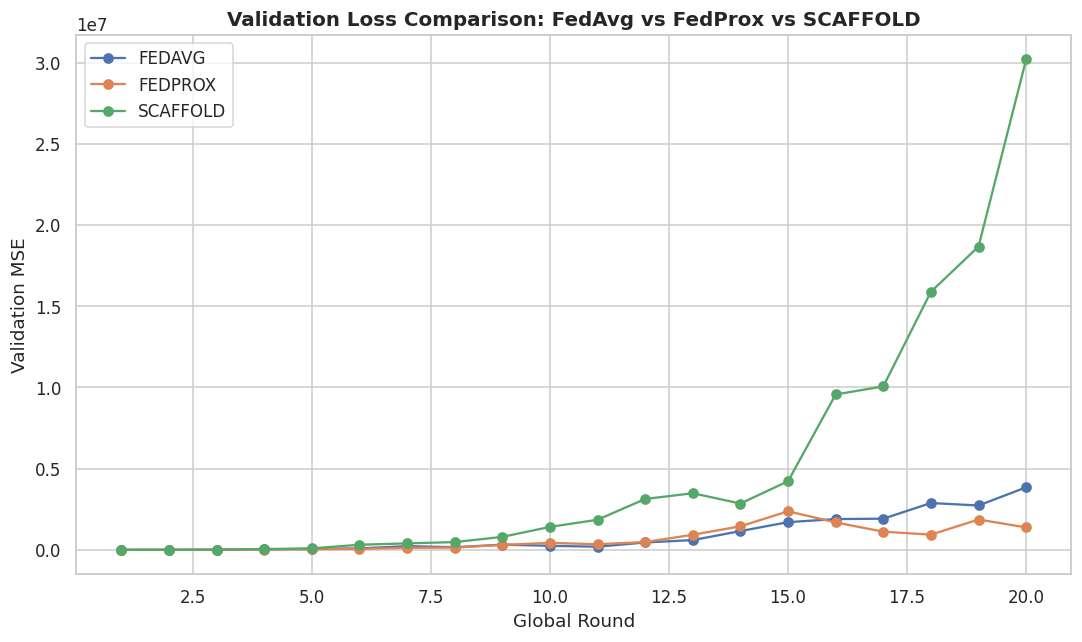

In [16]:
import matplotlib.pyplot as plt
import os
import pandas as pd

# Define the variables that were set in the config cell
STRATEGIES = ["fedavg", "fedprox", "scaffold"]
OUTPUT_DIR = "/kaggle/working/fed_clients"

plt.figure(figsize=(10, 6))
for strategy in STRATEGIES:
    df = pd.read_csv(os.path.join(OUTPUT_DIR, f"metrics_{strategy}.csv"))
    curve = df.groupby("round")["validation_loss"].first()
    plt.plot(curve.index, curve.values, marker="o", label=strategy.upper())

plt.title("Validation Loss Comparison: FedAvg vs FedProx vs SCAFFOLD", fontsize=13, fontweight="bold")
plt.xlabel("Global Round")
plt.ylabel("Validation MSE")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "strategy_comparison_validation.png"), dpi=300)
plt.show()

## 8b. Strategy Comparison — FedAvg vs. FedProx vs. SCAFFOLD

Validation-loss curves, per-metric bar charts (accuracy/F1/AUC/clustering accuracy), and
total training time for all three strategies, side by side, so the best-performing
strategy can be selected objectively in the next section.

### Defines a reusable function that loads one strategy's saved model and scores it on the untouched test set two ways: (A) as an anomaly detector (accuracy/precision/recall/F1/ROC-AUC) and (B) as a clustering method on its learned representations. This function is what actually runs the comparison in the next cells.

In [17]:
def evaluate_strategy(model_path, strategy_name):
    """
    Load a saved model, compute anomaly detection and clustering metrics
    on the held‑out test set.
    """
    # Load model
    model = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
    model.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, model_path), map_location=DEVICE))
    model.eval()

    # --- Anomaly detection threshold from validation benign set ---
    val_benign = val_global[val_global["labels"] == "benign"]
    benign_errors, _ = extract(val_benign, model)
    threshold = benign_errors.mean() + 2 * benign_errors.std()

    # --- Test inference ---
    test_labels = test_df["labels"].values
    test_errors, test_latents = extract(test_df, model)

    # Anomaly detection metrics
    y_true = (test_labels != "benign").astype(int)
    y_pred = (test_errors > threshold).astype(int)

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, test_errors)

    # Clustering metrics
    num_classes = len(np.unique(test_labels))
    kmeans = KMeans(n_clusters=num_classes, random_state=SEED, n_init=10)
    cluster_preds = kmeans.fit_predict(test_latents)

    def clustering_accuracy(y_true, y_pred):
        classes = np.unique(y_true)
        cls2int = {c: i for i, c in enumerate(classes)}
        y_true_int = np.array([cls2int[c] for c in y_true])
        n_clusters = len(np.unique(y_pred))
        n_classes = len(classes)
        size = max(n_clusters, n_classes)
        cost = np.zeros((size, size), dtype=np.int64)
        for t, p in zip(y_true_int, y_pred):
            cost[p, t] -= 1
        row_ind, col_ind = linear_sum_assignment(cost)
        mapping = dict(zip(row_ind, col_ind))
        mapped = np.array([mapping.get(p, -1) for p in y_pred])
        return float(np.mean(mapped == y_true_int))

    clust_acc = clustering_accuracy(test_labels, cluster_preds)
    nmi = normalized_mutual_info_score(test_labels, cluster_preds)
    ari = adjusted_rand_score(test_labels, cluster_preds)

    if len(test_latents) > 20000:
        sample_idx = np.random.default_rng(SEED).choice(len(test_latents), 20000, replace=False)
        sil = silhouette_score(test_latents[sample_idx], cluster_preds[sample_idx])
    else:
        sil = silhouette_score(test_latents, cluster_preds)

    return {
        "Strategy": strategy_name,
        "Threshold": threshold,
        "Anomaly_Accuracy": acc,
        "Anomaly_Precision": prec,
        "Anomaly_Recall": rec,
        "Anomaly_F1": f1,
        "Anomaly_AUC": auc,
        "Clustering_Accuracy": clust_acc,
        "Clustering_NMI": nmi,
        "Clustering_ARI": ari,
        "Clustering_Silhouette": sil,
    }


# --- Evaluate all strategies ---
results_list = []
for strategy in STRATEGIES:
    print(f"\nEvaluating {strategy.upper()} model...")
    res = evaluate_strategy(f"global_model_{strategy}.pt", strategy.upper())
    results_list.append(res)

comparison_df = pd.DataFrame(results_list)
comparison_df.to_csv(os.path.join(OUTPUT_DIR, "strategy_comparison_metrics.csv"), index=False)

print("\n" + "=" * 70)
print("COMPARISON TABLE: FedAvg vs FedProx vs SCAFFOLD")
print("=" * 70)
print(comparison_df.to_string(index=False))


Evaluating FEDAVG model...

Evaluating FEDPROX model...

Evaluating SCAFFOLD model...

COMPARISON TABLE: FedAvg vs FedProx vs SCAFFOLD
Strategy    Threshold  Anomaly_Accuracy  Anomaly_Precision  Anomaly_Recall  Anomaly_F1  Anomaly_AUC  Clustering_Accuracy  Clustering_NMI  Clustering_ARI  Clustering_Silhouette
  FEDAVG 3.588674e+05          0.530395           0.999934        0.519212    0.683513     0.953880             0.590311        0.630280        0.536253               0.688147
 FEDPROX 1.157789e+05          0.543695           0.999927        0.532835    0.695211     0.956994             0.618091        0.670334        0.565763               0.740337
SCAFFOLD 2.498585e+06          0.527220           0.999943        0.515957    0.680689     0.955611             0.616615        0.670583        0.567185               0.724709


### Draws four side-by-side bar charts — one per metric (accuracy, F1, ROC-AUC, clustering accuracy) — comparing FedAvg vs FedProx vs SCAFFOLD, so the three strategies can be compared at a glance.

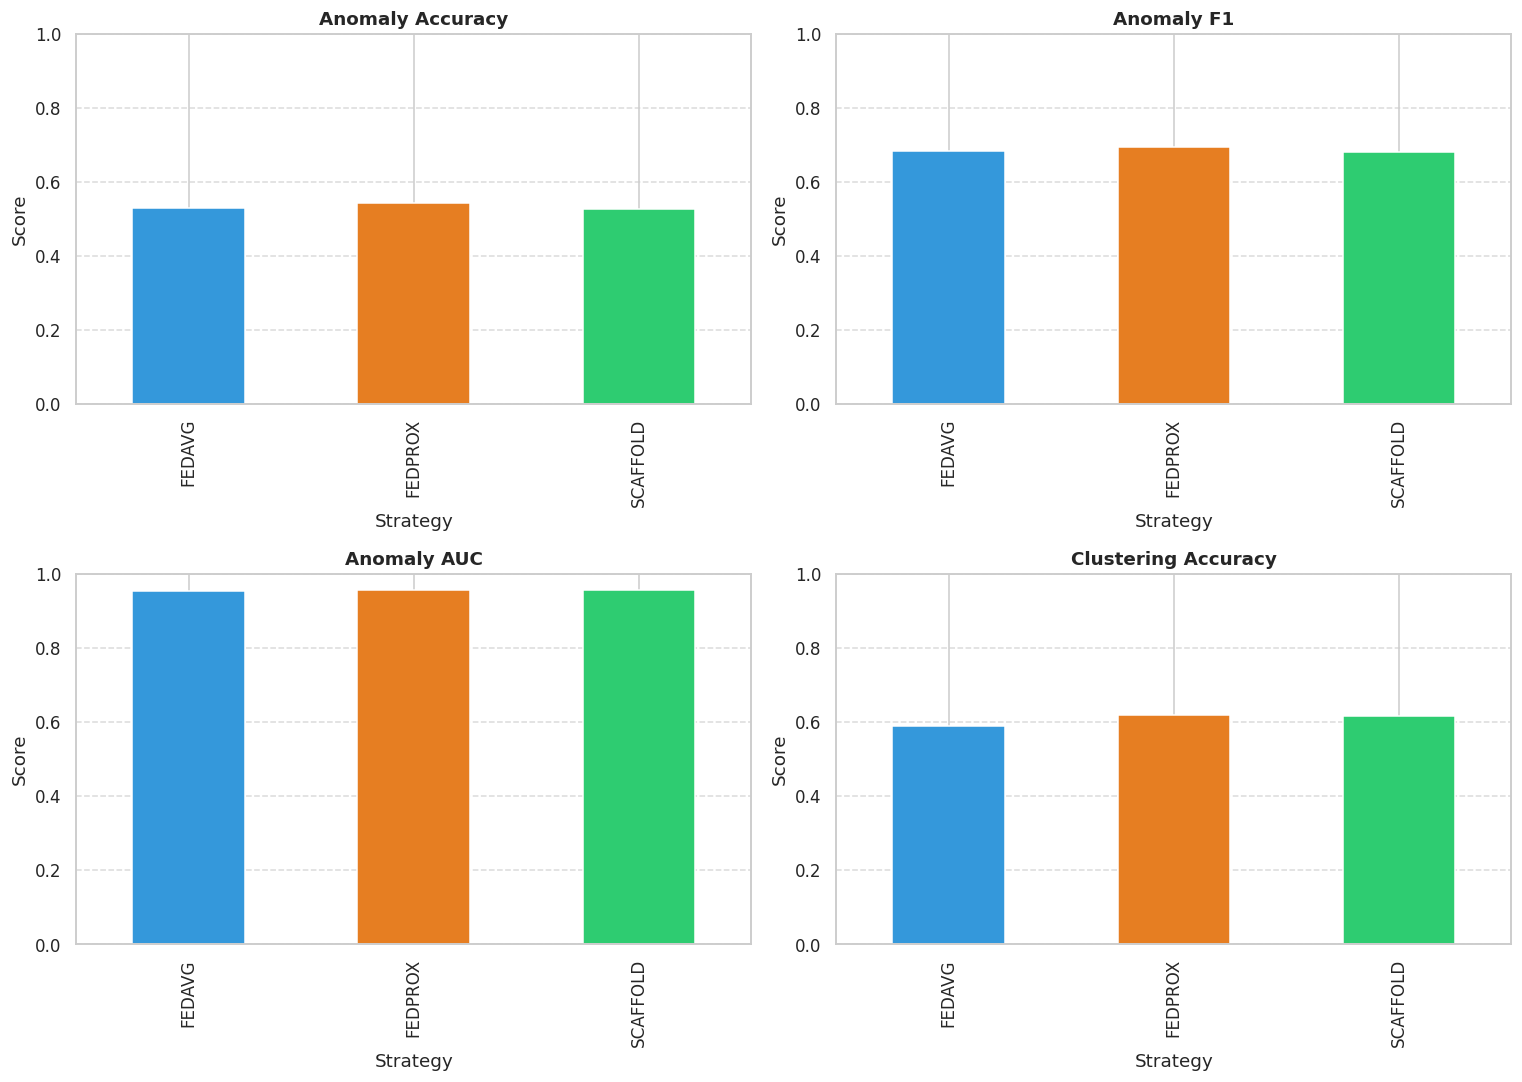

In [18]:
metrics_to_plot = ["Anomaly_Accuracy", "Anomaly_F1", "Anomaly_AUC", "Clustering_Accuracy"]

comparison_df.set_index("Strategy", inplace=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics_to_plot):
    comparison_df[metric].plot(kind="bar", ax=axes[i], color=["#3498db", "#e67e22", "#2ecc71"])
    axes[i].set_title(metric.replace("_", " "), fontsize=12, fontweight="bold")
    axes[i].set_ylabel("Score")
    axes[i].set_ylim(0, 1.0)
    axes[i].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "strategy_comparison_barcharts.png"), dpi=300)
plt.show()

### Builds one combined table with every strategy's final validation error and total training time, merges it with the metrics table from the previous cells, saves it to disk, and prints it out.

In [19]:
# Load training times from metrics files
summary_rows = []
for strategy in STRATEGIES:
    df = pd.read_csv(os.path.join(OUTPUT_DIR, f"metrics_{strategy}.csv"))
    final_val = df.groupby("round")["validation_loss"].last().iloc[-1]
    total_time = df["round_time_sec"].sum()
    summary_rows.append({
        "Strategy": strategy.upper(),
        "Final Val MSE": final_val,
        "Total Training Time (s)": total_time,
    })

time_df = pd.DataFrame(summary_rows)
final_comparison = comparison_df.merge(time_df, on="Strategy", how="left")
final_comparison.to_csv(os.path.join(OUTPUT_DIR, "final_comparison_full.csv"), index=False)

print("\n" + "=" * 70)
print("FULL COMPARISON (including training time)")
print("=" * 70)
print(final_comparison.to_string(index=False))


FULL COMPARISON (including training time)
Strategy    Threshold  Anomaly_Accuracy  Anomaly_Precision  Anomaly_Recall  Anomaly_F1  Anomaly_AUC  Clustering_Accuracy  Clustering_NMI  Clustering_ARI  Clustering_Silhouette  Final Val MSE  Total Training Time (s)
  FEDAVG 3.588674e+05          0.530395           0.999934        0.519212    0.683513     0.953880             0.590311        0.630280        0.536253               0.688147      3850567.2               306.655390
 FEDPROX 1.157789e+05          0.543695           0.999927        0.532835    0.695211     0.956994             0.618091        0.670334        0.565763               0.740337      1381018.2               361.465232
SCAFFOLD 2.498585e+06          0.527220           0.999943        0.515957    0.680689     0.955611             0.616615        0.670583        0.567185               0.724709     30203460.0              1365.577769


## 9. Evaluation Setup — Best-Strategy Selection & Inference on the Held-Out Test Set

The best strategy is picked from the §8b comparison table by **ROC-AUC** (the most
threshold-independent metric), and that strategy's saved global model is reloaded —
earlier versions of this notebook accidentally evaluated whichever strategy trained
*last* (SCAFFOLD) regardless of which performed best; this is now fixed explicitly.

The model is switched to `eval()` mode and run over the WiFi-MQTT **test** split (never
seen during training) to obtain, per sample:
- the **reconstruction MSE** (used for anomaly detection), and
- the **32-dim latent vector** (used for clustering).

The anomaly-detection **threshold** is calibrated on **known-benign traffic from the
held-out validation set** (mean + 2·std of its reconstruction error) — labels are used
here purely for calibration/evaluation, never to inform the model's weights — and then
applied, unchanged, to the fully held-out test set.

### Picks the single **best** strategy out of the three (by ROC-AUC) and reloads *that* strategy's saved model — everything from here on evaluates only this best model. It then calibrates the anomaly-detection cut-off ("threshold") using only benign traffic from the validation set, and runs the model once over the full test set to get a reconstruction-error score and a 32-number latent vector for every test row.

In [20]:
# BUG FIX: `global_model` at this point is left over from the training
# loop and holds whichever strategy trained LAST (SCAFFOLD) -- NOT
# necessarily the best-performing one. Everything below (threshold
# calibration, test-set evaluation, clustering, final summary) was
# silently scoring SCAFFOLD instead of your best model. Explicitly pick
# the best strategy from the comparison table above (by ROC-AUC, the
# most threshold-independent metric) and reload THAT model.
BEST_METRIC = "Anomaly_AUC"   # change to "Anomaly_Accuracy" / "Anomaly_F1" if you prefer
best_strategy_name = comparison_df[BEST_METRIC].idxmax()   # comparison_df is indexed by Strategy
print(f"Best strategy by {BEST_METRIC}: {best_strategy_name}")

global_model = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
global_model.load_state_dict(torch.load(
    os.path.join(OUTPUT_DIR, f"global_model_{best_strategy_name.lower()}.pt"), map_location=DEVICE
))
global_model.eval()

# ------------------------------------------------------------------
# Extract benign errors from the VALIDATION set (unseen during training)
# ------------------------------------------------------------------
val_benign = val_global[val_global["labels"] == "benign"]
benign_errors, _ = extract(val_benign, global_model)
threshold = benign_errors.mean() + 2 * benign_errors.std()

# ------------------------------------------------------------------
# Run inference on the held-out TEST set
# ------------------------------------------------------------------
test_labels = test_df["labels"].values
test_errors, test_latents = extract(test_df, global_model)

print(f"Calibration (validation benign, n={len(val_benign):,}): "
      f"mean={benign_errors.mean():.6f}  std={benign_errors.std():.6f}")
print(f"Anomaly threshold (benign mean + 2*std): {threshold:.6f}")
print(f"Test set: {len(test_df):,} samples | recon-error mean={test_errors.mean():.6f} "
      f"std={test_errors.std():.6f}")

Best strategy by Anomaly_AUC: FEDPROX
Calibration (validation benign, n=38,546): mean=4845.756348  std=55466.562500
Anomaly threshold (benign mean + 2*std): 115778.882812
Test set: 1,612,117 samples | recon-error mean=1453002.000000 std=5593207.000000


## 10. Evaluation (A) — Reconstruction-Error Anomaly Detection

Any test sample whose reconstruction MSE exceeds the calibrated threshold is flagged
as an anomaly (attack); everything else is classified as normal (benign). A
per-attack-category breakdown follows, showing which specific attack types (if any)
are dragging overall recall down versus which are already well-detected. Later cells
(§13) re-tune the threshold using an F1-optimal search and an ROC/target-false-positive-rate
approach, since precision has substantial headroom in this dataset.

### Using the threshold from the previous cell, every test row above the threshold is flagged as an anomaly (attack) and everything below it as normal. This cell prints the headline numbers for the chosen best strategy: Accuracy, Precision, Recall, F1-score, and ROC-AUC.

In [21]:
y_true = (test_labels != "benign").astype(int)     # 1 = attack / anomaly
y_pred = (test_errors > threshold).astype(int)

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
auc = roc_auc_score(y_true, test_errors)

print("=" * 60)
print("(A) RECONSTRUCTION-ERROR ANOMALY DETECTION")
print("=" * 60)
print(f"Threshold : {threshold:.6f}")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {auc:.4f}")

(A) RECONSTRUCTION-ERROR ANOMALY DETECTION
Threshold : 115778.882812
Accuracy  : 0.5437
Precision : 0.9999
Recall    : 0.5328
F1-score  : 0.6952
ROC-AUC   : 0.9570


### Breaks the overall recall number down **per attack type**, so you can see exactly which of the 18 attacks are detected well and which are being missed, instead of only seeing one blended average. Prints a table and a bar chart, sorted worst-detected first.

Per-category detection rate at the current threshold (lowest first -- these categories are what's dragging overall recall down):
          Category      N  Detection_rate  Mean_recon_error
 dos_publish_flood   8505        0.001999      4.974596e+03
      arp_spoofing   1744        0.002867      2.028532e+04
           dos_udp 137553        0.064113      1.218917e+05
          ddos_udp 362070        0.079007      1.897484e+05
 dos_connect_flood   3131        0.082402      7.682693e+04
ddos_publish_flood   8416        0.091492      2.146872e+05
        ping_sweep    186        0.096774      8.537283e+04
           dos_tcp  82096        0.104439      7.630398e+04
          ddos_tcp 182597        0.129915      8.660919e+04
    malformed_data   1747        0.143675      3.310986e+04
vulnerability_scan   1011        0.394659      1.092624e+06
ddos_connect_flood  41916        0.638062      2.070759e+05
           os_scan   3495        0.859514      2.293976e+07
         port_scan  20921      

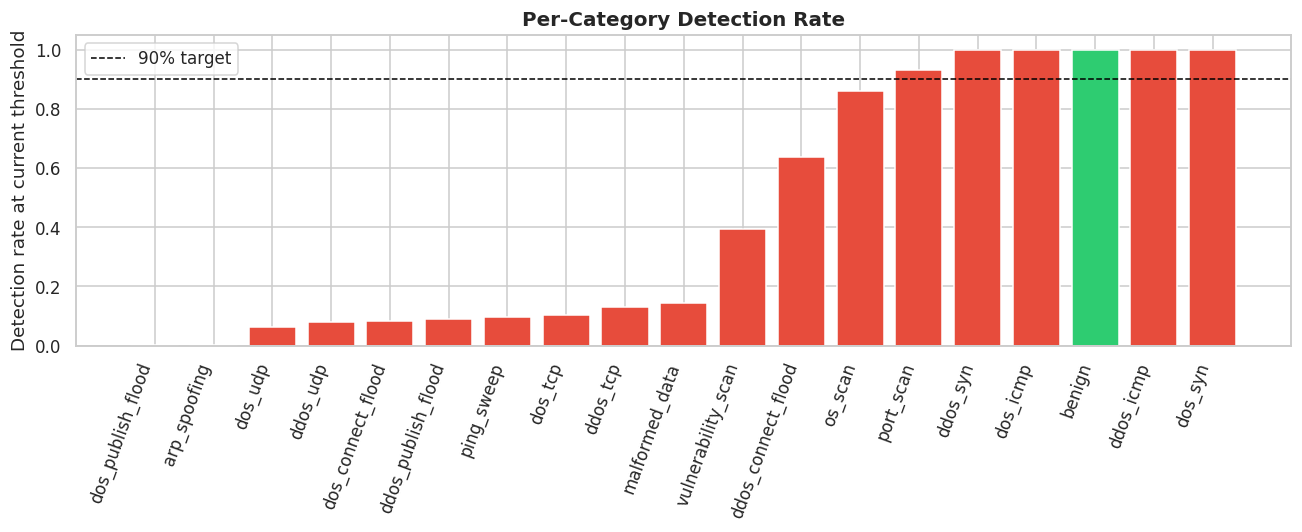

In [22]:
# ------------------------------------------------------------------------
# Diagnostic: per-attack-category detection rate at the current threshold.
# Overall recall (~0.53) is an average -- this breaks it down by attack
# type so you can see whether recall is uniformly mediocre everywhere, or
# whether a handful of "stealthy" categories (traffic that looks close to
# benign) are dragging the average down while most categories are already
# detected well.
# ------------------------------------------------------------------------
per_class_rows = []
for lbl in sorted(pd.unique(test_labels)):
    mask = test_labels == lbl
    n = int(mask.sum())
    if lbl == "benign":
        rate = 1 - y_pred[mask].mean()   # fraction correctly kept as benign (specificity)
    else:
        rate = y_pred[mask].mean()       # fraction correctly flagged as anomaly (recall for this class)
    per_class_rows.append({
        "Category": lbl, "N": n,
        "Detection_rate": rate,
        "Mean_recon_error": float(test_errors[mask].mean()),
    })

per_class_df = pd.DataFrame(per_class_rows).sort_values("Detection_rate")
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_category_detection_rate.csv"), index=False)
print("Per-category detection rate at the current threshold (lowest first -- "
      "these categories are what's dragging overall recall down):")
print(per_class_df.to_string(index=False))

plt.figure(figsize=(12, 5))
colors = ["#2ecc71" if c == "benign" else "#e74c3c" for c in per_class_df["Category"]]
plt.bar(per_class_df["Category"], per_class_df["Detection_rate"], color=colors)
plt.axhline(0.9, color="black", linestyle="--", linewidth=1, label="90% target")
plt.xticks(rotation=70, ha="right")
plt.ylabel("Detection rate at current threshold")
plt.title("Per-Category Detection Rate", fontsize=13, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "per_category_detection_rate.png"), dpi=300)
plt.show()

### Plots the distribution of reconstruction-error scores separately for benign traffic (green) and attack traffic (red), with the decision threshold marked as a dashed line — a visual way of seeing how well-separated normal and attack traffic are.

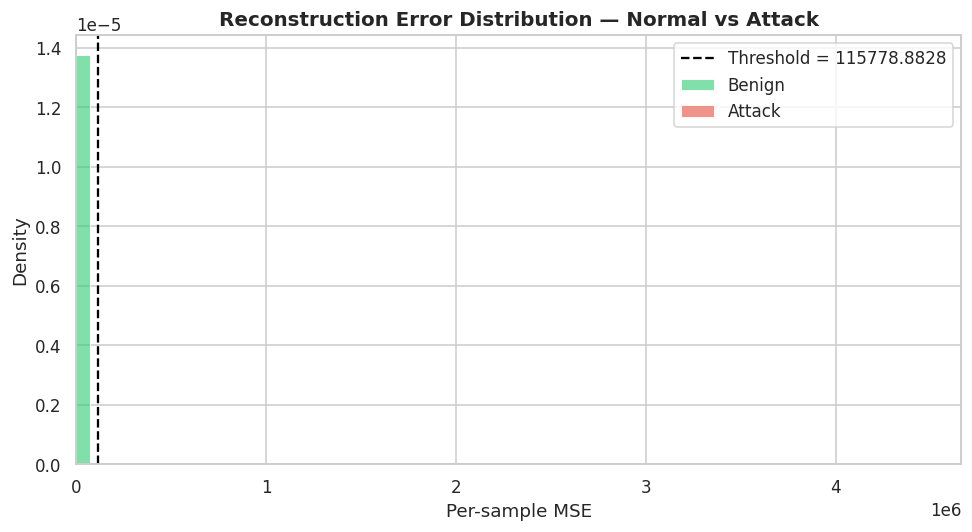

In [23]:
# Reconstruction-error distribution: normal vs attack
plt.figure(figsize=(9, 5))
sns.histplot(test_errors[y_true == 0], bins=80, color="#2ecc71", label="Benign",
             stat="density", alpha=0.6)
sns.histplot(test_errors[y_true == 1], bins=80, color="#e74c3c", label="Attack",
             stat="density", alpha=0.6)
plt.axvline(threshold, color="black", linestyle="--", label=f"Threshold = {threshold:.4f}")
plt.title("Reconstruction Error Distribution — Normal vs Attack", fontsize=13, fontweight="bold")
plt.xlabel("Per-sample MSE")
plt.ylabel("Density")
plt.xlim(0, np.percentile(test_errors, 99.5))
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "reconstruction_error_distribution.png"), dpi=300)
plt.show()

### Produces the **overall 2×2 confusion matrix** for the whole test set (Normal vs Anomaly, predicted vs actual) at the chosen threshold. 

## > 📍 **This is one of the main "total result" outputs of the notebook** — it shows, in one picture, how many of the ~1.7 million test rows were correctly/incorrectly classified overall.

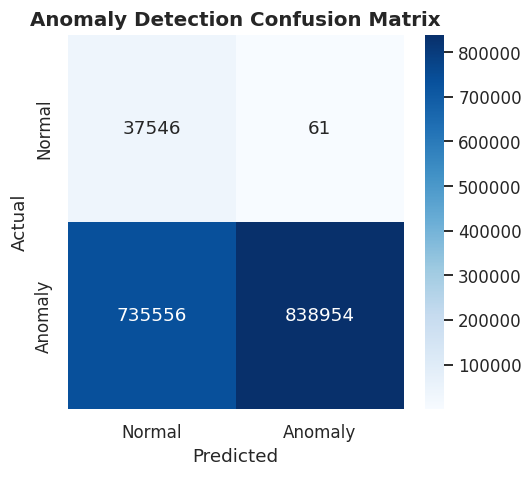

In [24]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.title("Anomaly Detection Confusion Matrix", fontsize=13, fontweight="bold")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "anomaly_confusion_matrix.png"), dpi=300)
plt.show()

### Plots the ROC curve (True Positive Rate vs False Positive Rate across every possible threshold) and reports the ROC-AUC score — a single number (closer to 1.0 is better) summarising how well the model separates attacks from benign traffic regardless of the exact threshold chosen.

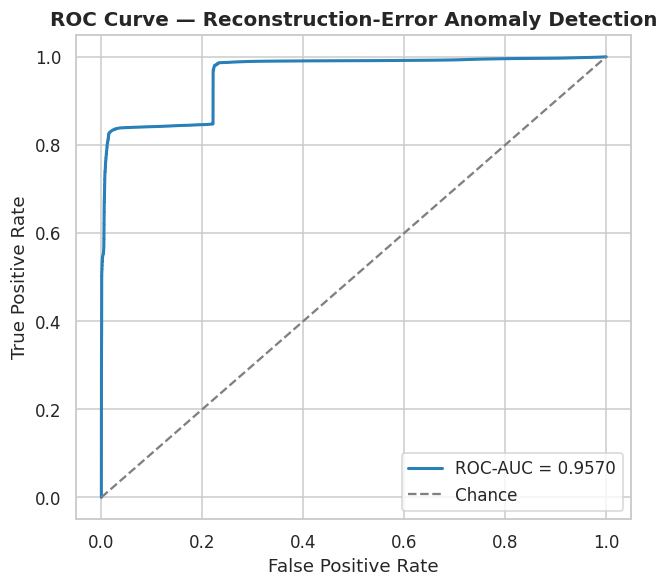

In [25]:
# ROC curve
fpr, tpr, _ = roc_curve(y_true, test_errors)
plt.figure(figsize=(6, 5.5))
plt.plot(fpr, tpr, color="#2980b9", linewidth=2, label=f"ROC-AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.title("ROC Curve — Reconstruction-Error Anomaly Detection", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_curve.png"), dpi=300)
plt.show()

## 10a. Confusion Matrix for Each of the 18 Attack Types

The overall confusion matrix in the previous section blends all 18 attack types together into one "Anomaly" class. This section breaks that apart: for **each of the 18 attack categories individually**, it builds a confusion matrix against benign traffic (Normal vs Anomaly, predicted vs actual), so you can see exactly which attacks the model catches almost perfectly and which ones it struggles with — this lines up with the per-category detection-rate table from Section 9, just shown as a full confusion matrix per attack instead of a single detection-rate number.

Matrices are sorted **worst accuracy first**, so the attacks that need the most attention appear at the top-left of the grid.


Per-attack confusion matrix summary (sorted worst accuracy first):
            Attack      N     TP     FN  TN_benign  FP_benign  Accuracy  Precision   Recall       F1
          ddos_udp 362070  28606 333464      37546         61  0.165514   0.997872 0.079007 0.146421
           dos_udp 137553   8819 128734      37546         61  0.264701   0.993131 0.064113 0.120451
          ddos_tcp 182597  23722 158875      37546         61  0.278233   0.997435 0.129915 0.229887
           dos_tcp  82096   8574  73522      37546         61  0.385287   0.992936 0.104439 0.188998
ddos_connect_flood  41916  26745  15171      37546         61  0.808458   0.997724 0.638062 0.778353
 dos_publish_flood   8505     17   8488      37546         61  0.814604   0.217949 0.001999 0.003961
ddos_publish_flood   8416    770   7646      37546         61  0.832540   0.926594 0.091492 0.166540
 dos_connect_flood   3131    258   2873      37546         61  0.927979   0.808777 0.082402 0.149565
      arp_spoofing   174

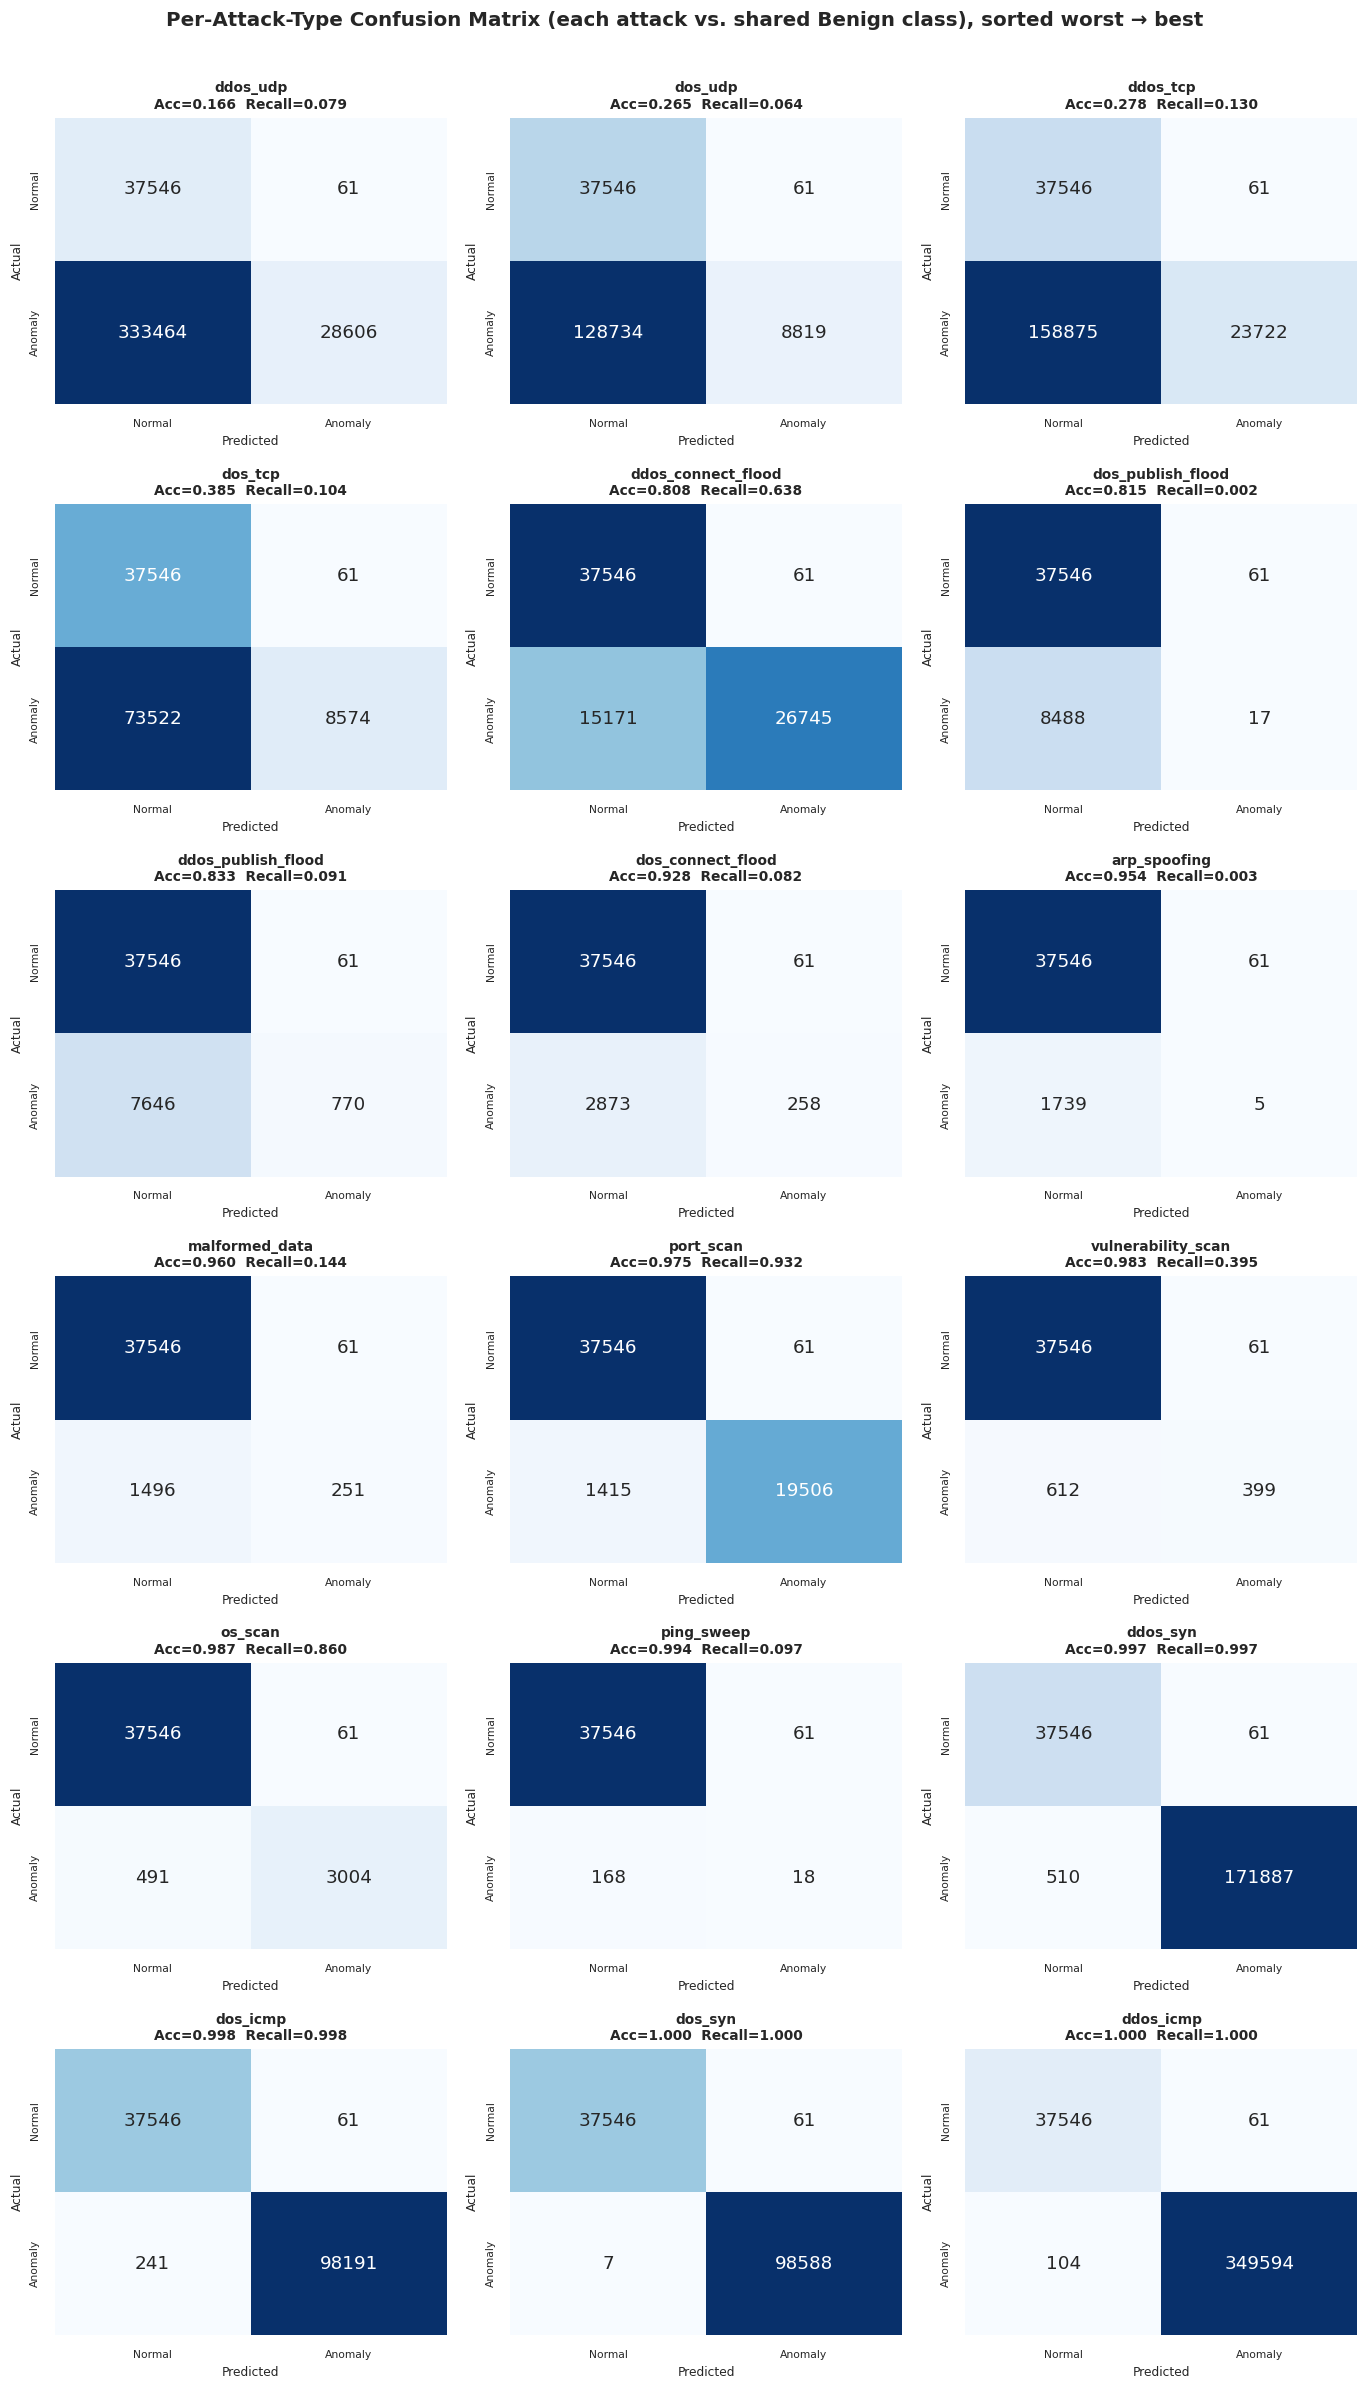

In [26]:
# ------------------------------------------------------------------------
# Confusion matrix for EACH of the 18 individual attack categories, each
# measured against the shared benign class (Normal vs Anomaly), using the
# best strategy's predictions (y_pred / test_errors / threshold) computed
# in Section 9-10 above. Sorted worst accuracy first.
# ------------------------------------------------------------------------
attack_categories = sorted(c for c in pd.unique(test_labels) if c != "benign")

benign_mask = (test_labels == "benign")
tn_all = int((y_pred[benign_mask] == 0).sum())   # benign correctly kept normal
fp_all = int((y_pred[benign_mask] == 1).sum())   # benign wrongly flagged as anomaly

per_attack_rows = []
for attack in attack_categories:
    mask = (test_labels == attack)
    tp = int((y_pred[mask] == 1).sum())          # attack correctly flagged
    fn = int((y_pred[mask] == 0).sum())          # attack missed (called normal)

    acc = (tp + tn_all) / (tp + tn_all + fp_all + fn)
    prec = tp / (tp + fp_all) if (tp + fp_all) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0

    per_attack_rows.append({
        "Attack": attack, "N": int(mask.sum()),
        "TP": tp, "FN": fn, "TN_benign": tn_all, "FP_benign": fp_all,
        "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
    })

per_attack_df = pd.DataFrame(per_attack_rows).sort_values("Accuracy").reset_index(drop=True)
per_attack_df.to_csv(os.path.join(OUTPUT_DIR, "per_attack_confusion_summary.csv"), index=False)
print("Per-attack confusion matrix summary (sorted worst accuracy first):")
print(per_attack_df.to_string(index=False))

n_attacks = len(per_attack_df)
ncols = 3
nrows = int(np.ceil(n_attacks / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.6 * nrows))
axes = axes.flatten()

for i, row in per_attack_df.iterrows():
    ax = axes[i]
    cm = np.array([[row["TN_benign"], row["FP_benign"]], [row["FN"], row["TP"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
    ax.set_title(f"{row['Attack']}\nAcc={row['Accuracy']:.3f}  Recall={row['Recall']:.3f}",
                 fontsize=9, fontweight="bold")
    ax.set_xlabel("Predicted", fontsize=8)
    ax.set_ylabel("Actual", fontsize=8)
    ax.tick_params(labelsize=7)

for j in range(n_attacks, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Per-Attack-Type Confusion Matrix (each attack vs. shared Benign class), "
             "sorted worst \u2192 best", fontsize=13, fontweight="bold", y=1.005)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "per_attack_confusion_matrices.png"), dpi=300)
plt.show()


## 11. Evaluation (B) — Latent-Space Clustering

The 32-dim latent vectors learned by the (unsupervised) encoder are clustered with
`KMeans(k = number of true classes)`. Because cluster IDs are arbitrary, the
**Hungarian algorithm** finds the optimal cluster→class assignment before computing
clustering accuracy.

### This is Evaluation (B) — a completely different way of judging the model, using only the 32-number latent vectors (not the reconstruction error). It groups the test rows into clusters with KMeans and checks how well those clusters line up with the *true* attack labels, printing Clustering Accuracy, NMI, ARI and Silhouette score.

In [27]:
def clustering_accuracy(y_true, y_pred):
    '''Best-match clustering accuracy via the Hungarian algorithm.'''
    classes = np.unique(y_true)
    cls2int = {c: i for i, c in enumerate(classes)}
    y_true_int = np.array([cls2int[c] for c in y_true])

    n_clusters = len(np.unique(y_pred))
    n_classes = len(classes)
    size = max(n_clusters, n_classes)
    cost = np.zeros((size, size), dtype=np.int64)
    for t, p in zip(y_true_int, y_pred):
        cost[p, t] -= 1     # negative counts -> Hungarian minimizes cost = maximizes overlap

    row_ind, col_ind = linear_sum_assignment(cost)
    mapping = dict(zip(row_ind, col_ind))
    mapped = np.array([mapping.get(p, -1) for p in y_pred])
    return float(np.mean(mapped == y_true_int))


num_classes = len(np.unique(test_labels))
kmeans = KMeans(n_clusters=num_classes, random_state=SEED, n_init=10)
cluster_preds = kmeans.fit_predict(test_latents)

clust_acc = clustering_accuracy(test_labels, cluster_preds)
nmi = normalized_mutual_info_score(test_labels, cluster_preds)
ari = adjusted_rand_score(test_labels, cluster_preds)

if len(test_latents) > 20000:
    sample_idx = np.random.default_rng(SEED).choice(len(test_latents), 20000, replace=False)
    sil = silhouette_score(test_latents[sample_idx], cluster_preds[sample_idx])
else:
    sil = silhouette_score(test_latents, cluster_preds)

print("=" * 60)
print("(B) LATENT-SPACE CLUSTERING")
print("=" * 60)
print(f"Clusters (k)           : {num_classes}")
print(f"Clustering Accuracy    : {clust_acc:.4f}")
print(f"Normalized Mutual Info : {nmi:.4f}")
print(f"Adjusted Rand Index    : {ari:.4f}")
print(f"Silhouette Score       : {sil:.4f}")

(B) LATENT-SPACE CLUSTERING
Clusters (k)           : 19
Clustering Accuracy    : 0.6181
Normalized Mutual Info : 0.6703
Adjusted Rand Index    : 0.5658
Silhouette Score       : 0.7403


### Draws a heatmap crosstab showing, for every true attack category, which KMeans cluster its rows mostly landed in — a visual check of how cleanly the model's learned representation separates the different attack types.

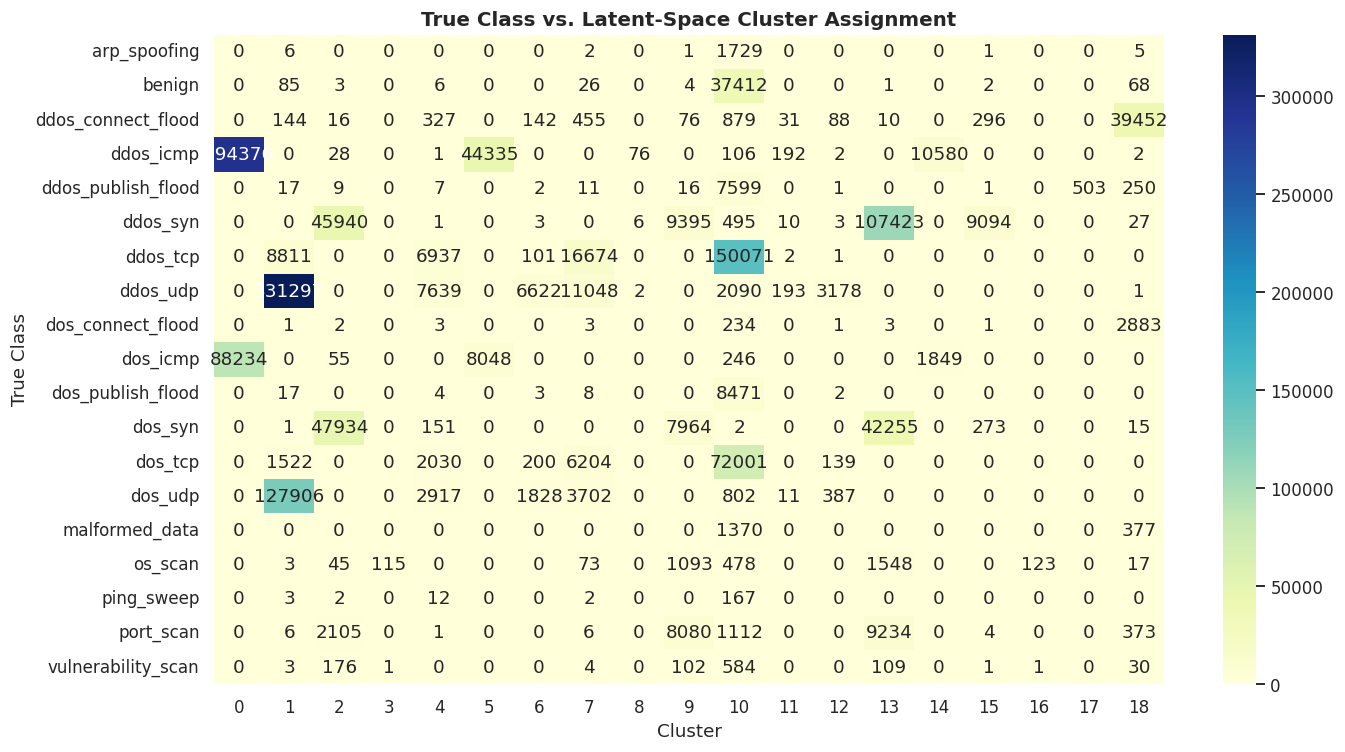

In [28]:
# True class vs assigned cluster crosstab heatmap
ct = pd.crosstab(pd.Series(test_labels, name="True Class"),
                  pd.Series(cluster_preds, name="Cluster"))
plt.figure(figsize=(13, 7))
sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu")
plt.title("True Class vs. Latent-Space Cluster Assignment", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "clustering_crosstab_heatmap.png"), dpi=300)
plt.show()

## 12. Final Summary

All key metrics, timing statistics, and generated artefacts in one place.

### Collects **every key metric computed anywhere in this notebook** — anomaly-detection accuracy/precision/recall/F1/ROC-AUC, the threshold used, all four clustering metrics, and training-time stats — into one single table, saves it to disk, and lists every output file that has been generated. 

> 📍 **This is the main "everything in one place" summary table** — if your guide only looks at one cell's output in the whole notebook, this is the one to show her.

In [29]:
summary = pd.DataFrame([
    {"Metric": "Anomaly Detection Accuracy",       "Value": acc},
    {"Metric": "Anomaly Detection Precision",      "Value": prec},
    {"Metric": "Anomaly Detection Recall",         "Value": rec},
    {"Metric": "Anomaly Detection F1-score",       "Value": f1},
    {"Metric": "Anomaly Detection ROC-AUC",        "Value": auc},
    {"Metric": "Anomaly Threshold",                "Value": threshold},
    {"Metric": "Clustering Accuracy",              "Value": clust_acc},
    {"Metric": "Clustering NMI",                   "Value": nmi},
    {"Metric": "Clustering ARI",                   "Value": ari},
    {"Metric": "Clustering Silhouette",             "Value": sil},
    {"Metric": "Total Federated Training Time (s)", "Value": total_time},
    {"Metric": "Avg Time per Round (s)",            "Value": total_time / NUM_ROUNDS},
])
summary.to_csv(os.path.join(OUTPUT_DIR, "final_summary_metrics.csv"), index=False)

print("=" * 70)
print("FINAL SUMMARY — CICIoMT-2024 WiFi-MQTT | Federated CNN Autoencoder")
print("=" * 70)
print(summary.to_string(index=False))

print("\nArtefacts saved under:", OUTPUT_DIR)
for fname in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", fname)

FINAL SUMMARY — CICIoMT-2024 WiFi-MQTT | Federated CNN Autoencoder
                           Metric         Value
       Anomaly Detection Accuracy      0.982573
      Anomaly Detection Precision      0.867391
         Anomaly Detection Recall      0.394659
       Anomaly Detection F1-score      0.542488
        Anomaly Detection ROC-AUC      0.956994
                Anomaly Threshold 115778.882812
              Clustering Accuracy      0.618091
                   Clustering NMI      0.670334
                   Clustering ARI      0.565763
            Clustering Silhouette      0.740337
Total Federated Training Time (s)   1365.577769
           Avg Time per Round (s)     68.278888

Artefacts saved under: /kaggle/working/fed_clients
 - anomaly_confusion_matrix.png
 - attack_frequency_distribution.png
 - client_1.csv
 - client_10.csv
 - client_2.csv
 - client_3.csv
 - client_4.csv
 - client_5.csv
 - client_6.csv
 - client_7.csv
 - client_8.csv
 - client_9.csv
 - client_distribution.csv


###  The simple threshold used earlier (benign mean + 2×std) is just a reasonable starting guess, not necessarily the best one. This cell searches the validation set for the threshold that maximises the F1-score instead, does this separately for all three strategies, and re-evaluates each of them on the test set with its own tuned threshold.

In [30]:
from sklearn.metrics import f1_score, precision_recall_curve
import numpy as np

# BUG FIX: the previous version searched only the 50th-99.9th percentile of
# the full (attack-dominated) validation error distribution, which
# structurally excludes the low-error region right above the small benign
# cluster -- exactly where the real optimal threshold lives. precision_recall_curve
# instead evaluates every achievable threshold in the data and is vectorized.
best_thresholds = {}

for strategy in STRATEGIES:
    model = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
    state_dict = torch.load(os.path.join(OUTPUT_DIR, f"global_model_{strategy}.pt"), map_location=DEVICE)
    model.load_state_dict(state_dict)
    model.eval()

    val_labels = val_global["labels"].values
    val_errors, _ = extract(val_global, model)
    val_y_true = (val_labels != "benign").astype(int)

    precisions, recalls, pr_thresholds = precision_recall_curve(val_y_true, val_errors)
    f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    f1s = f1s[:-1]   # last precision/recall point has no corresponding threshold
    best_idx = int(np.argmax(f1s))
    best_threshold = float(pr_thresholds[best_idx])
    best_f1 = float(f1s[best_idx])

    best_thresholds[strategy] = best_threshold
    print(f"{strategy.upper()}: Best threshold = {best_threshold:.6f}, Val F1 = {best_f1:.4f}")

print("\n" + "="*70)
print("RE‑EVALUATION ON TEST SET WITH TUNED THRESHOLDS")
print("="*70)

tuned_results = []
for strategy in STRATEGIES:
    model = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
    state_dict = torch.load(os.path.join(OUTPUT_DIR, f"global_model_{strategy}.pt"), map_location=DEVICE)
    model.load_state_dict(state_dict)
    model.eval()

    test_labels = test_df["labels"].values
    test_errors, _ = extract(test_df, model)
    y_true = (test_labels != "benign").astype(int)

    thresh = best_thresholds[strategy]
    y_pred = (test_errors > thresh).astype(int)

    tuned_results.append({
        "Strategy": strategy.upper(),
        "Tuned_Threshold": thresh,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_true, test_errors),
    })

tuned_df = pd.DataFrame(tuned_results)
print(tuned_df.to_string(index=False))
tuned_df.to_csv(os.path.join(OUTPUT_DIR, "tuned_test_metrics.csv"), index=False)
print("\n✅ Tuned metrics saved to", os.path.join(OUTPUT_DIR, "tuned_test_metrics.csv"))

FEDAVG: Best threshold = 3701.388672, Val F1 = 0.9939
FEDPROX: Best threshold = 3711.973389, Val F1 = 0.9935
SCAFFOLD: Best threshold = 111341.054688, Val F1 = 0.9941

RE‑EVALUATION ON TEST SET WITH TUNED THRESHOLDS
Strategy  Tuned_Threshold  Accuracy  Precision   Recall       F1      AUC
  FEDAVG      3701.388672  0.984386   0.993024 0.990974 0.991998 0.953880
 FEDPROX      3711.973389  0.982476   0.993499 0.988526 0.991006 0.956994
SCAFFOLD    111341.054688  0.985018   0.993208 0.991441 0.992323 0.955611

✅ Tuned metrics saved to /kaggle/working/fed_clients/tuned_test_metrics.csv


## 13. Threshold Re-Tuning — F1-Optimal and Target-FPR Alternatives

The default mean+2·std threshold is a simple heuristic, not the optimal operating point.
This section searches the full validation precision-recall curve for the F1-maximizing
threshold, then offers an alternative: picking a threshold directly off the ROC curve for
a target false-positive rate (default 5%), since precision stays near 1.0 across a wide
range of thresholds here — meaning there's usually room to trade a small, explicit amount
of false alarms for materially higher recall.

### Offers a second, alternative way of picking a threshold: instead of optimising F1, it picks the point on the ROC curve that keeps false alarms on benign traffic at (or below) a chosen target rate (5% here), then reports how each strategy performs on the test set at that operating point.

In [31]:
# ------------------------------------------------------------------------
# Alternative threshold selection: pick the operating point directly off
# the ROC curve for a target false-positive rate, instead of an F1-only
# search. In this dataset precision stays ~1.0 across a huge range of
# thresholds (benign is a small minority of traffic), so F1 barely moves
# with FPR -- picking straight off the ROC curve gives an explicit,
# interpretable recall/false-alarm-rate tradeoff instead. Given precision
# has so much headroom, it is usually safe to accept a somewhat higher
# FPR in exchange for materially higher recall.
# ------------------------------------------------------------------------
TARGET_FPR = 0.05  # tune this: fraction of BENIGN traffic you're willing to false-alarm on

roc_threshold_results = []
for strategy in STRATEGIES:
    model = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
    model.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, f"global_model_{strategy}.pt"), map_location=DEVICE))
    model.eval()

    val_labels_all = val_global["labels"].values
    val_y_true = (val_labels_all != "benign").astype(int)
    val_errors_all, _ = extract(val_global, model)

    fpr_v, tpr_v, thresh_v = roc_curve(val_y_true, val_errors_all)
    idx = np.where(fpr_v <= TARGET_FPR)[0]
    chosen_idx = idx[-1] if len(idx) > 0 else 0
    chosen_threshold = thresh_v[chosen_idx]

    test_errors_s, _ = extract(test_df, model)
    y_pred_s = (test_errors_s > chosen_threshold).astype(int)
    y_true_s = (test_df["labels"].values != "benign").astype(int)

    roc_threshold_results.append({
        "Strategy": strategy.upper(),
        "Target_FPR": TARGET_FPR,
        "Chosen_Threshold": chosen_threshold,
        "Val_TPR_at_target": tpr_v[chosen_idx],
        "Test_Accuracy": accuracy_score(y_true_s, y_pred_s),
        "Test_Precision": precision_score(y_true_s, y_pred_s, zero_division=0),
        "Test_Recall": recall_score(y_true_s, y_pred_s, zero_division=0),
        "Test_F1": f1_score(y_true_s, y_pred_s, zero_division=0),
    })

roc_thresh_df = pd.DataFrame(roc_threshold_results)
roc_thresh_df.to_csv(os.path.join(OUTPUT_DIR, "roc_target_fpr_thresholds.csv"), index=False)
print(f"Threshold chosen per strategy for target FPR <= {TARGET_FPR} (tune TARGET_FPR above and re-run):")
print(roc_thresh_df.to_string(index=False))

Threshold chosen per strategy for target FPR <= 0.05 (tune TARGET_FPR above and re-run):
Strategy  Target_FPR  Chosen_Threshold  Val_TPR_at_target  Test_Accuracy  Test_Precision  Test_Recall  Test_F1
  FEDAVG        0.05      31050.703125           0.716290       0.782825        0.996913     0.780053 0.875250
 FEDPROX        0.05      14988.073242           0.824506       0.843334        0.996266     0.842750 0.913101
SCAFFOLD        0.05     436705.843750           0.823863       0.842614        0.997472     0.840986 0.912569


### Draws the confusion matrix for **all three strategies side by side**, using the ROC-tuned threshold from the previous cell, with the exact True-Positive / False-Positive / False-Negative / True-Negative counts printed above each strategy's matrix. 

> 📍 This is the final side-by-side comparison of all three federated strategies at their best operating point.

FEDAVG (threshold=31050.703125): TN=33,804 FP=3,803 FN=346,309 TP=1,228,201  (Recall=0.7801, Precision=0.9969)
FEDPROX (threshold=14988.073242): TN=32,634 FP=4,973 FN=247,591 TP=1,326,919  (Recall=0.8428, Precision=0.9963)
SCAFFOLD (threshold=436705.843750): TN=34,251 FP=3,356 FN=250,369 TP=1,324,141  (Recall=0.8410, Precision=0.9975)


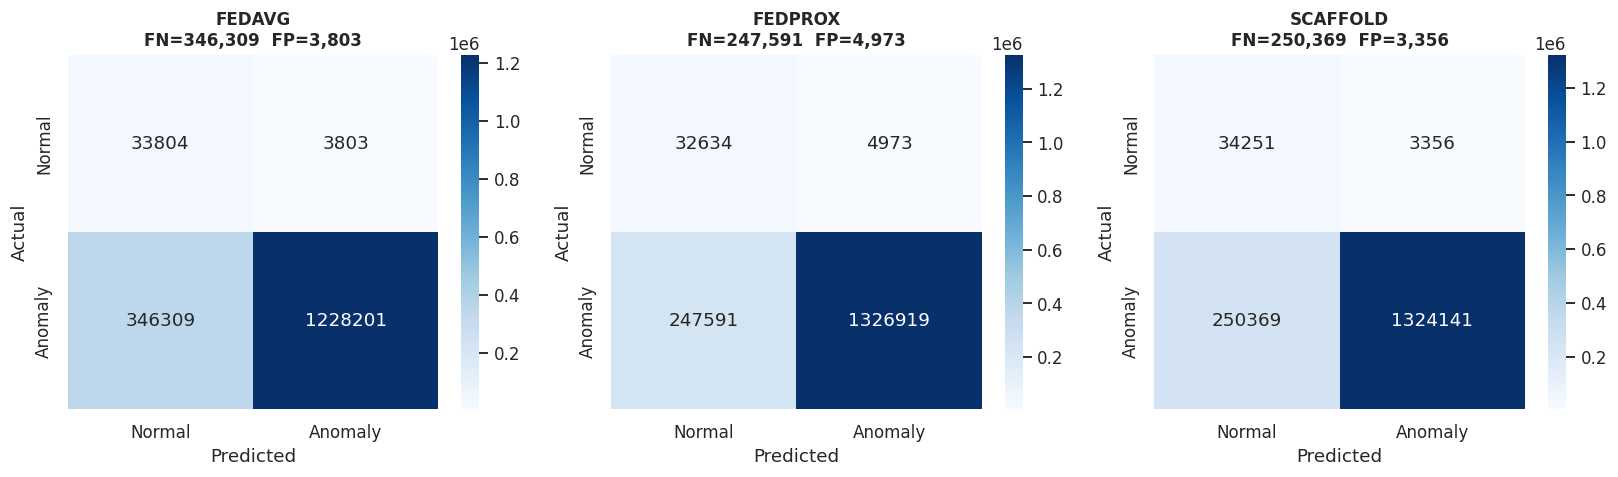

In [32]:
# ------------------------------------------------------------------------
# Confusion matrices at the ROC-tuned (TARGET_FPR) threshold for each
# strategy — uses roc_thresh_df from the previous cell.
# ------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(STRATEGIES), figsize=(5 * len(STRATEGIES), 4.5))
if len(STRATEGIES) == 1:
    axes = [axes]

for ax, strategy in zip(axes, STRATEGIES):
    model = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
    model.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, f"global_model_{strategy}.pt"), map_location=DEVICE))
    model.eval()

    thresh = roc_thresh_df.loc[roc_thresh_df["Strategy"] == strategy.upper(), "Chosen_Threshold"].values[0]

    test_errors_s, _ = extract(test_df, model)
    y_true_s = (test_df["labels"].values != "benign").astype(int)
    y_pred_s = (test_errors_s > thresh).astype(int)

    cm = confusion_matrix(y_true_s, y_pred_s)
    tn, fp, fn, tp = cm.ravel()

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
    ax.set_title(f"{strategy.upper()}\nFN={fn:,}  FP={fp:,}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    print(f"{strategy.upper()} (threshold={thresh:.6f}): "
          f"TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}  "
          f"(Recall={tp/(tp+fn):.4f}, Precision={tp/(tp+fp):.4f})")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_roc_tuned.png"), dpi=300)
plt.show()

## 14. 🏁 FINAL CONSOLIDATED RESULTS — Before vs. After Threshold Tuning (all in one place)

This last section pulls **everything together in a single cell** so you don't have to scroll
back through the notebook to compare numbers:

1. **All 3 strategies, at every threshold setting** — default threshold, F1-optimal tuned
   threshold, and ROC target-FPR tuned threshold — side by side.
2. For the **best strategy** ( chosen automatically by ROC-AUC earlier): the confusion
   matrix **before tuning** (default mean+2·std threshold) and **after tuning** (F1-optimal
   threshold), shown side by side so you can see exactly what tuning changed.
3. A **full confusion matrix across all attack categories** (all 19 classes — benign + all 18
   attacks, not just the first 10) for the best strategy, built by matching each latent-space
   cluster to its closest true attack category.

The cell re-loads the best strategy's model fresh and recomputes everything itself, so it
does not depend on which strategy any earlier cell in Section 13 happened to leave loaded.


ALL STRATEGIES -- DEFAULT THRESHOLD (mean + 2*std of benign val error)
          Anomaly_Accuracy  Anomaly_Precision  Anomaly_Recall  Anomaly_F1  Anomaly_AUC
Strategy                                                                              
FEDAVG            0.530395           0.999934        0.519212    0.683513     0.953880
FEDPROX           0.543695           0.999927        0.532835    0.695211     0.956994
SCAFFOLD          0.527220           0.999943        0.515957    0.680689     0.955611

ALL STRATEGIES -- F1-OPTIMAL TUNED THRESHOLD
Strategy  Tuned_Threshold  Accuracy  Precision   Recall       F1      AUC
  FEDAVG      3701.388672  0.984386   0.993024 0.990974 0.991998 0.953880
 FEDPROX      3711.973389  0.982476   0.993499 0.988526 0.991006 0.956994
SCAFFOLD    111341.054688  0.985018   0.993208 0.991441 0.992323 0.955611

ALL STRATEGIES -- ROC TARGET-FPR TUNED THRESHOLD (FPR <= 0.05)
Strategy  Target_FPR  Chosen_Threshold  Val_TPR_at_target  Test_Accuracy  Test_Precision

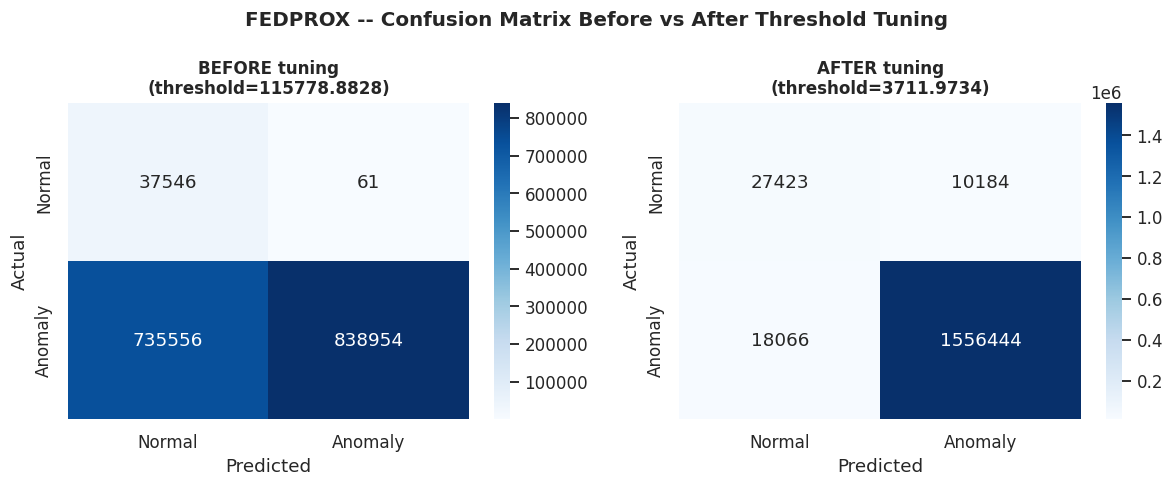

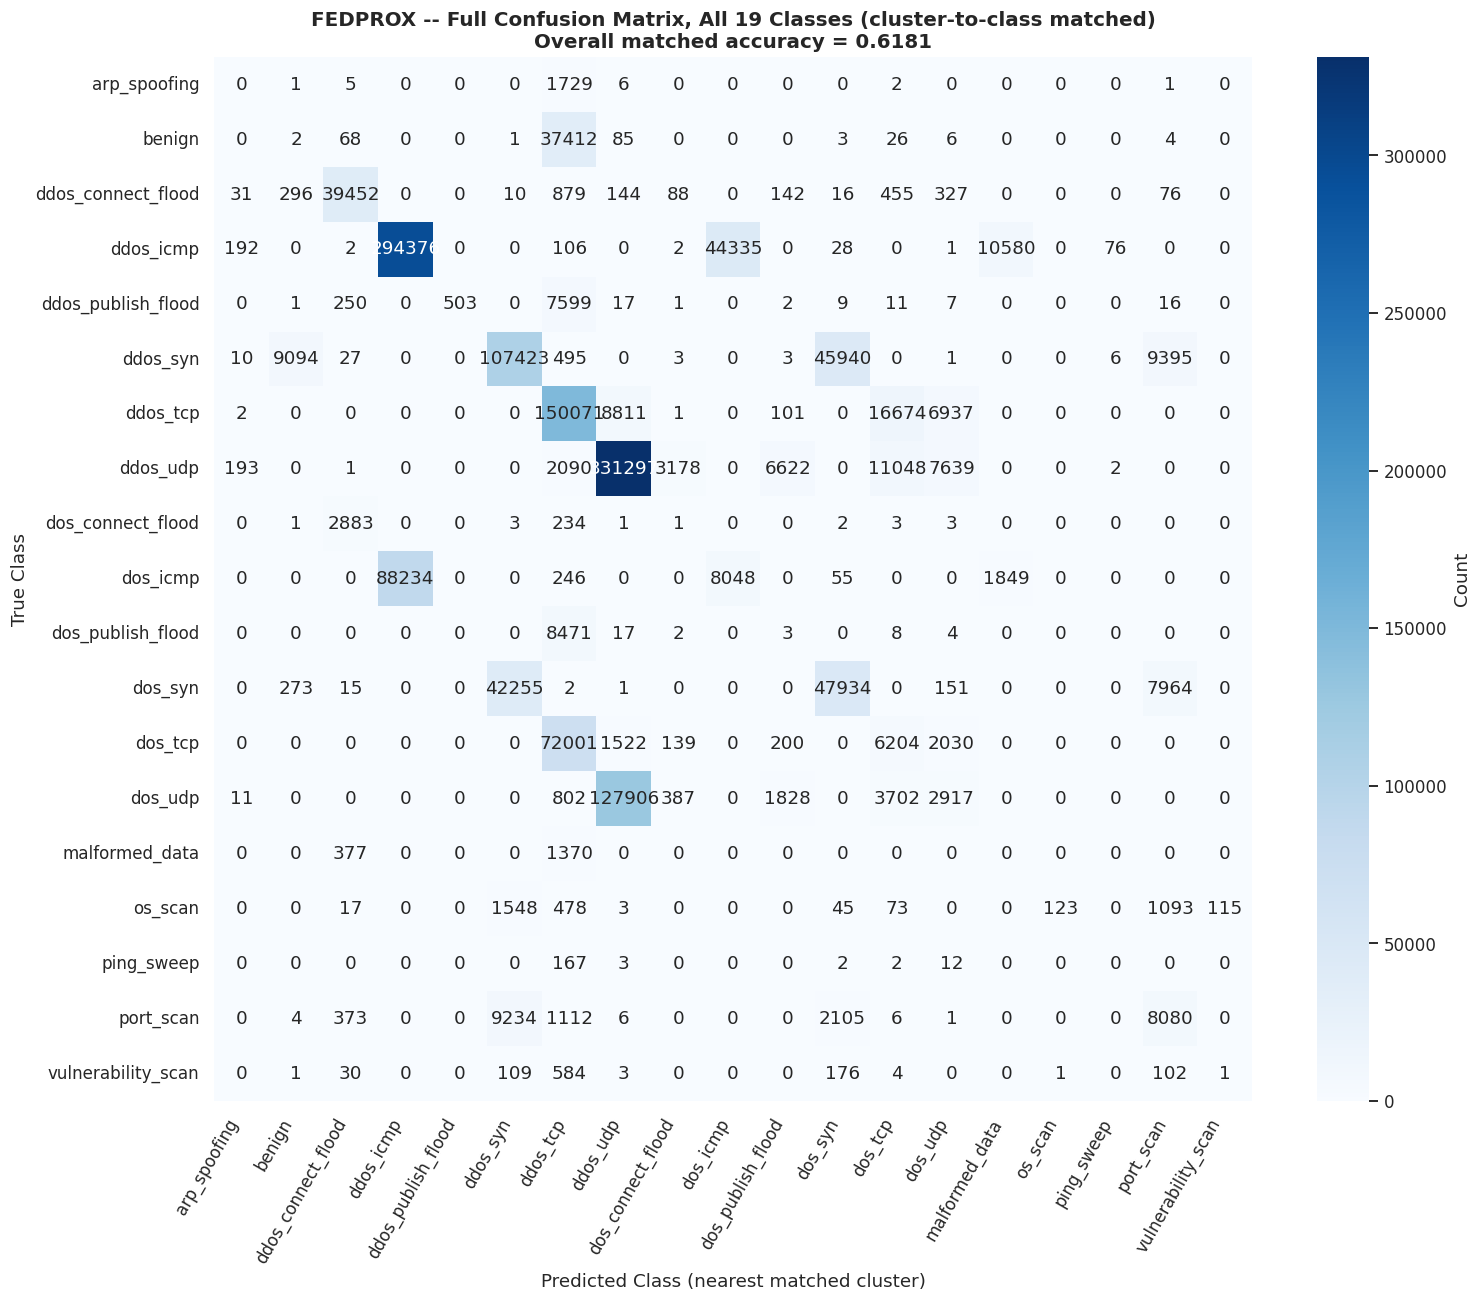


Full 19-class matched accuracy: 0.6181


In [33]:
# ============================================================================
# FINAL CONSOLIDATED RESULTS -- everything in one place
# (1) all strategies x all threshold settings, (2) best strategy confusion
# matrix before vs. after tuning, (3) full all-19-class confusion matrix.
# ============================================================================
from scipy.optimize import linear_sum_assignment

# ----------------------------------------------------------------------
# 1) ALL STRATEGIES x ALL THRESHOLD SETTINGS, side by side
# ----------------------------------------------------------------------
print("=" * 78)
print("ALL STRATEGIES -- DEFAULT THRESHOLD (mean + 2*std of benign val error)")
print("=" * 78)
print(comparison_df[["Anomaly_Accuracy", "Anomaly_Precision", "Anomaly_Recall",
                      "Anomaly_F1", "Anomaly_AUC"]].to_string())

print("\n" + "=" * 78)
print("ALL STRATEGIES -- F1-OPTIMAL TUNED THRESHOLD")
print("=" * 78)
print(tuned_df.to_string(index=False))

print("\n" + "=" * 78)
print(f"ALL STRATEGIES -- ROC TARGET-FPR TUNED THRESHOLD (FPR <= {TARGET_FPR})")
print("=" * 78)
print(roc_thresh_df.to_string(index=False))

# ----------------------------------------------------------------------
# 2) BEST STRATEGY -- BEFORE vs AFTER TUNING (fresh, self-contained reload
#    so this doesn't depend on whichever strategy the loops above left
#    loaded in memory)
# ----------------------------------------------------------------------
best_model_final = CNNAutoencoder(PADDED_LEN, LATENT_DIM).to(DEVICE)
best_model_final.load_state_dict(torch.load(
    os.path.join(OUTPUT_DIR, f"global_model_{best_strategy_name.lower()}.pt"),
    map_location=DEVICE
))
best_model_final.eval()

val_benign_final = val_global[val_global["labels"] == "benign"]
benign_errors_final, _ = extract(val_benign_final, best_model_final)
default_threshold_final = benign_errors_final.mean() + 2 * benign_errors_final.std()
tuned_threshold_final = best_thresholds[best_strategy_name.lower()]

test_labels_final = test_df["labels"].values
test_errors_final, test_latents_final = extract(test_df, best_model_final)
y_true_final = (test_labels_final != "benign").astype(int)

y_pred_before = (test_errors_final > default_threshold_final).astype(int)
y_pred_after = (test_errors_final > tuned_threshold_final).astype(int)

def _summarize(y_true, y_pred, scores, stage, thresh):
    return {
        "Stage": stage,
        "Threshold": thresh,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, scores),
    }

before_after_df = pd.DataFrame([
    _summarize(y_true_final, y_pred_before, test_errors_final,
               "BEFORE tuning (mean+2std)", default_threshold_final),
    _summarize(y_true_final, y_pred_after, test_errors_final,
               "AFTER tuning (F1-optimal)", tuned_threshold_final),
])

print("\n" + "=" * 78)
print(f"BEST STRATEGY ({best_strategy_name}) -- BEFORE vs AFTER THRESHOLD TUNING")
print("=" * 78)
print(before_after_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, y_pred_stage, title in zip(
    axes, [y_pred_before, y_pred_after],
    [f"BEFORE tuning\n(threshold={default_threshold_final:.4f})",
     f"AFTER tuning\n(threshold={tuned_threshold_final:.4f})"]
):
    cm_stage = confusion_matrix(y_true_final, y_pred_stage)
    sns.heatmap(cm_stage, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle(f"{best_strategy_name} -- Confusion Matrix Before vs After Threshold Tuning",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "final_before_after_confusion_matrices.png"), dpi=300)
plt.show()

# ----------------------------------------------------------------------
# 3) FULL ALL-CLASS CONFUSION MATRIX (all 19 classes: benign + 18 attacks)
#    for the best strategy, built by Hungarian-matching each KMeans
#    cluster to its closest true attack category.
# ----------------------------------------------------------------------
def hungarian_label_mapping(y_true_labels, cluster_ids):
    classes = np.unique(y_true_labels)
    cls2int = {c: i for i, c in enumerate(classes)}
    y_true_int = np.array([cls2int[c] for c in y_true_labels])
    n_clusters = len(np.unique(cluster_ids))
    n_classes = len(classes)
    size = max(n_clusters, n_classes)
    cost = np.zeros((size, size), dtype=np.int64)
    for t, p in zip(y_true_int, cluster_ids):
        cost[p, t] -= 1
    row_ind, col_ind = linear_sum_assignment(cost)
    cluster_to_class_idx = dict(zip(row_ind, col_ind))
    int2cls = {i: c for c, i in cls2int.items()}
    return np.array([
        int2cls.get(cluster_to_class_idx.get(p, -1), "unmatched_cluster")
        for p in cluster_ids
    ])

num_classes_final = len(np.unique(test_labels_final))
kmeans_final = KMeans(n_clusters=num_classes_final, random_state=SEED, n_init=10)
cluster_preds_final = kmeans_final.fit_predict(test_latents_final)
mapped_pred_labels = hungarian_label_mapping(test_labels_final, cluster_preds_final)

all_classes_sorted = sorted(np.unique(test_labels_final))
full_cm = confusion_matrix(test_labels_final, mapped_pred_labels, labels=all_classes_sorted)
full_cm_accuracy = np.trace(full_cm) / full_cm.sum()

plt.figure(figsize=(14, 12))
sns.heatmap(full_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=all_classes_sorted, yticklabels=all_classes_sorted,
            cbar_kws={"label": "Count"})
plt.title(f"{best_strategy_name} -- Full Confusion Matrix, All {num_classes_final} Classes "
          f"(cluster-to-class matched)\nOverall matched accuracy = {full_cm_accuracy:.4f}",
          fontsize=13, fontweight="bold")
plt.xlabel("Predicted Class (nearest matched cluster)")
plt.ylabel("True Class")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "final_all_class_confusion_matrix.png"), dpi=300)
plt.show()

print(f"\nFull {num_classes_final}-class matched accuracy: {full_cm_accuracy:.4f}")
